<a href="https://colab.research.google.com/github/swapnasaina274/malicious-mobile-app-detection/blob/main/byteplot%20work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/Malicious project work/Byteplots images")

print("Dataset path:", DATA_DIR)
print("Path exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for split in ["train", "test", "adv", "obfus"]:
        split_dir = DATA_DIR / split
        print(f"\n{split.upper()}")
        if split_dir.exists():
            for class_dir in sorted(split_dir.iterdir()):
                if class_dir.is_dir():
                    count = sum(
                        1 for p in class_dir.iterdir()
                        if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
                    )
                    print(f"  {class_dir.name}: {count} images")
        else:
            print("  Folder not found")


Mounted at /content/drive
Dataset path: /content/drive/MyDrive/Malicious project work/Byteplots images
Path exists: False


In [7]:

from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Malicious project work/Byteplot images/Image"
)

print("Dataset path:", DATA_DIR)
print("Path exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("\nFolders found:")
    for item in sorted(DATA_DIR.iterdir()):
        if item.is_dir():
            print("📁", item.name)
else:
    print("\nFolder not found. Check the spelling of the folder names.")


Dataset path: /content/drive/MyDrive/Malicious project work/Byteplot images/Image
Path exists: True

Folders found:
📁 adv
📁 obfus
📁 test
📁 train


In [8]:

from pathlib import Path

EXPECTED_CLASSES = ["adware", "banking", "benign", "riskware", "sms"]
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

for split in ["train", "test", "adv", "obfus"]:
    split_dir = DATA_DIR / split
    print(f"\n{'=' * 35}")
    print(f"{split.upper()}")

    if not split_dir.exists():
        print("❌ Split folder missing!")
        continue

    total = 0

    for class_name in EXPECTED_CLASSES:
        class_dir = split_dir / class_name

        if not class_dir.exists():
            print(f"❌ {class_name}: folder missing")
            continue

        count = sum(
            1 for p in class_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        total += count
        print(f"{class_name:10s}: {count:,} images")

    print(f"Total:      {total:,} images")



TRAIN
adware    : 1,061 images
banking   : 1,733 images
benign    : 2,822 images
riskware  : 2,729 images
sms       : 3,341 images
Total:      11,686 images

TEST
adware    : 450 images
banking   : 720 images
benign    : 1,209 images
riskware  : 1,165 images
sms       : 1,464 images
Total:      5,008 images

ADV
adware    : 440 images
banking   : 647 images
benign    : 1,209 images
riskware  : 1,093 images
sms       : 1,451 images
Total:      4,840 images

OBFUS
adware    : 360 images
banking   : 603 images
benign    : 1,209 images
riskware  : 957 images
sms       : 1,418 images
Total:      4,547 images


In [9]:

from PIL import Image
from collections import Counter

from pathlib import Path

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

def inspect_images(split_name):
    split_dir = DATA_DIR / split_name

    total = 0
    corrupt = []
    dimensions = Counter()
    modes = Counter()

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for path in class_dir.iterdir():
            if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            total += 1

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    dimensions[img.size] += 1
                    modes[img.mode] += 1

            except Exception as exc:
                corrupt.append((str(path), str(exc)))

    print(f"\n--- {split_name.upper()} ---")
    print("Images checked:", total)
    print("Corrupt/unreadable:", len(corrupt))
    print("Most common dimensions:", dimensions.most_common(10))
    print("Image modes:", modes)

    if corrupt:
        print("\nFirst 5 problematic files:")
        for path, error in corrupt[:5]:
            print(path, "->", error)

inspect_images("train")
inspect_images("test")



--- TRAIN ---
Images checked: 11686
Corrupt/unreadable: 0
Most common dimensions: [((256, 256), 11686)]
Image modes: Counter({'RGB': 11686})

--- TEST ---
Images checked: 5008
Corrupt/unreadable: 0
Most common dimensions: [((256, 256), 5008)]
Image modes: Counter({'RGB': 5008})


In [10]:

from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

CLASS_NAMES = ["adware", "banking", "benign", "riskware", "sms"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

# Collect training image paths and their labels
all_paths = []
all_labels = []

for class_name in CLASS_NAMES:
    class_dir = DATA_DIR / "train" / class_name

    paths = sorted(
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    all_paths.extend(paths)
    all_labels.extend([CLASS_TO_IDX[class_name]] * len(paths))

# Split training data into train and validation sets
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.15,
    random_state=42,
    stratify=all_labels
)

print("Classes:", CLASS_TO_IDX)
print(f"\nTraining samples:   {len(train_paths):,}")
print(f"Validation samples: {len(val_paths):,}")
print(f"Original test set:  5,008")

print("\nTraining distribution:")
for idx, name in enumerate(CLASS_NAMES):
    print(f"{name:10s}: {sum(y == idx for y in train_labels):,}")

print("\nValidation distribution:")
for idx, name in enumerate(CLASS_NAMES):
    print(f"{name:10s}: {sum(y == idx for y in val_labels):,}")


Classes: {'adware': 0, 'banking': 1, 'benign': 2, 'riskware': 3, 'sms': 4}

Training samples:   9,933
Validation samples: 1,753
Original test set:  5,008

Training distribution:
adware    : 902
banking   : 1,473
benign    : 2,399
riskware  : 2,319
sms       : 2,840

Validation distribution:
adware    : 159
banking   : 260
benign    : 423
riskware  : 410
sms       : 501


In [11]:

import hashlib
from collections import defaultdict

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def collect_hashes(split_name):
    result = defaultdict(list)
    split_dir = DATA_DIR / split_name

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for path in class_dir.iterdir():
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                result[sha256_file(path)].append(
                    (str(path), class_dir.name)
                )

    return result

print("Hashing training images...")
train_hashes = collect_hashes("train")

print("Hashing test images...")
test_hashes = collect_hashes("test")

train_unique = set(train_hashes)
test_unique = set(test_hashes)
overlap = train_unique & test_unique

print("\n--- DUPLICATE CHECK ---")
print("Unique training file hashes:", len(train_unique))
print("Unique test file hashes:", len(test_unique))
print("Hashes shared across train/test:", len(overlap))

if overlap:
    print("\nExamples of matching files:")
    for h in list(overlap)[:5]:
        print("TRAIN:", train_hashes[h][0])
        print("TEST: ", test_hashes[h][0])
else:
    print("No exact byte-for-byte duplicates found across splits.")


Hashing training images...
Hashing test images...

--- DUPLICATE CHECK ---
Unique training file hashes: 8000
Unique test file hashes: 3642
Hashes shared across train/test: 483

Examples of matching files:
TRAIN: ('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/sms/d35a90f7f9e1f5027327d19e8ec3b608c4c4071d51e5ac91b5be7b959c235ee8f3da5f13adb88e1d251d6ce3728003b4.png', 'sms')
TEST:  ('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/test/sms/79e35e01054b957feaf153e19e10009240370de0581b1faec848d49196687a72f21039a37a4f30fa0e229707385aaf56.png', 'sms')
TRAIN: ('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/banking/9b239c76aa43b4ff1c8f780610c35c311aba1730ae7fc68e7b7707cf73175d9f.png', 'banking')
TEST:  ('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/test/banking/7ea5522784be8ca6abb915f052da7065f2d08b4008d9165679e71352271ebea1.png', 'banking')
TRAIN: ('/content/drive/MyDrive/Malicious project work/By

In [12]:

from collections import defaultdict

def find_label_conflicts(hash_map):
    conflicts = []

    for digest, entries in hash_map.items():
        labels = sorted(set(label for _, label in entries))
        if len(labels) > 1:
            conflicts.append((digest, labels, entries))

    return conflicts

train_conflicts = find_label_conflicts(train_hashes)
test_conflicts = find_label_conflicts(test_hashes)

print("Training hashes with conflicting labels:", len(train_conflicts))
print("Test hashes with conflicting labels:", len(test_conflicts))

print("\nChecking labels for shared train/test hashes...")
cross_split_conflicts = []

for digest in train_unique & test_unique:
    train_labels_for_hash = {
        label for _, label in train_hashes[digest]
    }
    test_labels_for_hash = {
        label for _, label in test_hashes[digest]
    }

    if train_labels_for_hash != test_labels_for_hash:
        cross_split_conflicts.append(
            (digest, train_labels_for_hash, test_labels_for_hash)
        )

print("Shared hashes with different label sets:", len(cross_split_conflicts))

for item in cross_split_conflicts[:5]:
    print(item)



Training hashes with conflicting labels: 6
Test hashes with conflicting labels: 2

Checking labels for shared train/test hashes...
Shared hashes with different label sets: 6
('0fdae90ce5ddd359210b0954bfdff7ef9645de8c80e76b5319eca30a4227c2bc', {'riskware'}, {'adware'})
('6c1ab35388672c095d1c0f739d6e40b527e88b2be0da236da67d61fda79b25de', {'riskware', 'banking'}, {'riskware'})
('bf605f7fd915af74915a21408e6b9eca051ceed113f693d4320ad4365264193f', {'riskware'}, {'riskware', 'banking'})
('76b8bb217971fada4b16bfb9a8f26e13dcf0801dd093720548f3c3fbb3cde056', {'riskware', 'banking'}, {'riskware'})
('520051ba8dfe5567e8fec9b7c2136d1eaf3051dd5e347e1730cde041c635b7a3', {'riskware', 'banking'}, {'banking'})


In [13]:

def print_conflicts(title, conflicts):
    print(f"\n{'=' * 60}")
    print(title)
    print(f"Number of conflicting hashes: {len(conflicts)}")

    for digest, labels, entries in conflicts:
        print(f"\nHash: {digest}")
        print("Labels:", labels)

        for path, label in entries:
            print(f"  [{label}] {path}")

print_conflicts("TRAINING LABEL CONFLICTS", train_conflicts)
print_conflicts("TEST LABEL CONFLICTS", test_conflicts)



TRAINING LABEL CONFLICTS
Number of conflicting hashes: 6

Hash: aabd3c95dbab818c07bc712ed78e294a4e82b3c7ef14632b5b8c13e95f04afce
Labels: ['adware', 'riskware']
  [adware] /content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/adware/00847524ec1e69b2cdd53205cd9725295e87094eeed1567b3efb12191ded24d2cee04b164ef6cc6a5fe57e32bfb63105.png
  [riskware] /content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/riskware/cee04b164ef6cc6a5fe57e32bfb63105.png

Hash: 520051ba8dfe5567e8fec9b7c2136d1eaf3051dd5e347e1730cde041c635b7a3
Labels: ['banking', 'riskware']
  [banking] /content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/banking/cf3bb1df9e5bfe617690e8a39d789c083d83ab634693efe2998f7a6f15a19185.png
  [banking] /content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/banking/b46303b6bb90218d29f18e0d902ec6dd0eb75e3dadbfc97a9aeb6de3f53e6612.png
  [banking] /content/drive/MyDrive/Malicious project work/Byteplot images/Image/tra

In [8]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Malicious project work")

for filename in ["class_to_hash.json", "hash_to_class.json"]:
    matches = list(PROJECT_DIR.rglob(filename))

    print(f"\n{filename}: {len(matches)} found")
    for path in matches:
        print(path)



class_to_hash.json: 1 found
/content/drive/MyDrive/Malicious project work/class_to_hash.json

hash_to_class.json: 1 found
/content/drive/MyDrive/Malicious project work/hash_to_class.json


In [9]:

import json
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Malicious project work")

for filename in ["class_to_hash.json", "hash_to_class.json"]:
    path = PROJECT_DIR / filename

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(f"\n{'=' * 50}")
    print(filename)
    print("Top-level type:", type(data).__name__)
    print("Number of top-level entries:", len(data))

    if isinstance(data, dict):
        for i, (key, value) in enumerate(data.items()):
            print(repr(key), "->", repr(value)[:250])
            if i >= 4:
                break
    elif isinstance(data, list):
        print("First 5 entries:", repr(data[:5]))



class_to_hash.json
Top-level type: dict
Number of top-level entries: 5
'adware' -> ['0015ae7c27688d45f79170dcea16131ce557912a1a0c5f3b6b0465ee0774a4521cf660303734c47286ca7b57954ba058', '002fb7803cd8c0549bc7eb023458618520a3f0939e6ece1235a296491a7a13832839f25511fc886011534b6d2f5bdf2e', '00567501fe3517b1bf6b363dd6c4d0972a77c591b0d7c245
'banking' -> ['000aec00a2b667aaf1224974aba7ee30b4b088e073368c605ee335fb8ee11b54', '002ca15a26a80f025a45041df9bee5120653393c5ca41bdaca5f79ddda6d2731', '007556ca146f4b2e9ac6bd51dc66be5130538d514f5aa04d60c1a0b079585ef3', '0076a7acfa0d6fbcdf0dac7eee15d4ab3659972dfe55
'benign' -> ['00070891aea5767d858be0ff82253e6637e274cd5e7315dd9d8639e8465ed717', '000aa1f313ddc02b9e365d5dcca92841eac4f40cb88f595fad0a872d14711536', '001248a66e178bebdfbdca691b841832d4b2c04ef295a17fbe9b35f726d10a21', '00216736d5b7a5f18e87769195d69e95da8da267f061
'riskware' -> ['000cc3026c6f458a8d57e0df258a1249', '000ec04e83c58c9ea372c2f874c07316', '00150cd8d63e5baad2375ea8e0d9b5fa', '001d7e1952829a

In [10]:

import json
from pathlib import Path
from collections import Counter, defaultdict

DATA_DIR = Path(
    "/content/drive/MyDrive/Malicious project work/Byteplot images/Image"
)
PROJECT_DIR = Path("/content/drive/MyDrive/Malicious project work")

with open(PROJECT_DIR / "hash_to_class.json", "r") as f:
    hash_to_class = json.load(f)

print("Mapping entries:", len(hash_to_class))
print("\nChecking image filename stems against the mapping...")

for split in ["train", "test", "adv", "obfus"]:
    split_dir = DATA_DIR / split
    if not split_dir.exists():
        continue

    counts = Counter()
    examples = defaultdict(list)

    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        folder_label = class_dir.name.lower()

        for img in class_dir.iterdir():
            if img.suffix.lower() not in {
                ".png", ".jpg", ".jpeg", ".bmp", ".webp"
            }:
                continue

            # Test whether the filename stem is a key in the mapping.
            file_hash = img.stem.lower()
            mapped_label = hash_to_class.get(file_hash)

            if mapped_label is None:
                counts["not_in_mapping"] += 1
            elif mapped_label.lower() == folder_label:
                counts["match"] += 1
            else:
                counts["label_conflict"] += 1
                if len(examples["conflict"]) < 5:
                    examples["conflict"].append(
                        (img.name, folder_label, mapped_label)
                    )

            counts["total"] += 1

    print(f"\n{split.upper()}: {dict(counts)}")
    if examples["conflict"]:
        print("Conflict examples (filename, folder label, mapped label):")
        for item in examples["conflict"]:
            print(" ", item)



Mapping entries: 16691

Checking image filename stems against the mapping...

TRAIN: {'match': 11683, 'total': 11686, 'not_in_mapping': 3}

TEST: {'match': 5008, 'total': 5008}

ADV: {'match': 4840, 'total': 4840}

OBFUS: {'match': 4547, 'total': 4547}


In [11]:

import json
from pathlib import Path
from collections import defaultdict

PROJECT_DIR = Path("/content/drive/MyDrive/Malicious project work")
DATA_DIR = PROJECT_DIR / "Byteplot images" / "Image"

with open(PROJECT_DIR / "class_to_hash.json", "r") as f:
    class_to_hash = json.load(f)

with open(PROJECT_DIR / "hash_to_class.json", "r") as f:
    hash_to_class = json.load(f)

# Check consistency between the two mappings
mapping_conflicts = []
hashes_in_class_lists = defaultdict(set)

for class_name, hashes in class_to_hash.items():
    for h in hashes:
        hashes_in_class_lists[h.lower()].add(class_name.lower())
        if hash_to_class.get(h) != class_name:
            mapping_conflicts.append((h, class_name, hash_to_class.get(h)))

print("Hashes listed in class_to_hash:", sum(map(len, class_to_hash.values())))
print("Hashes in hash_to_class:", len(hash_to_class))
print("Class-list/hash-map disagreements:", len(mapping_conflicts))
print("Hashes listed under multiple classes:",
      sum(len(labels) > 1 for labels in hashes_in_class_lists.values()))

if mapping_conflicts:
    print("\nFirst 10 mapping disagreements:")
    for item in mapping_conflicts[:10]:
        print(item)

# Print training filenames absent from the mapping
print("\nTraining images missing from hash_to_class:")
missing = []

for class_dir in sorted(p for p in (DATA_DIR / "train").iterdir() if p.is_dir()):
    for img in sorted(class_dir.iterdir()):
        if img.suffix.lower() not in {".png", ".jpg", ".jpeg", ".bmp", ".webp"}:
            continue
        if img.stem.lower() not in hash_to_class:
            missing.append((img.name, class_dir.name, str(img)))

for item in missing:
    print(item)

print("\nTotal missing:", len(missing))


Hashes listed in class_to_hash: 16691
Hashes in hash_to_class: 16691
Class-list/hash-map disagreements: 0
Hashes listed under multiple classes: 0

Training images missing from hash_to_class:
('a1f8288d8eb59287671c6f1bed8927c798fa7adae6416881b050286d704b6314 (1).png', 'benign', '/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/benign/a1f8288d8eb59287671c6f1bed8927c798fa7adae6416881b050286d704b6314 (1).png')
('6c621baa59a0b83eb518100f38377310 (1).png', 'riskware', '/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/riskware/6c621baa59a0b83eb518100f38377310 (1).png')
('b4efeaacde00bc71ff5e902bf9c12cbf (1).png', 'riskware', '/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/riskware/b4efeaacde00bc71ff5e902bf9c12cbf (1).png')

Total missing: 3


In [12]:

import hashlib
from pathlib import Path
from collections import defaultdict, Counter
import json

PROJECT_DIR = Path("/content/drive/MyDrive/Malicious project work")
DATA_DIR = PROJECT_DIR / "Byteplot images" / "Image"

with open(PROJECT_DIR / "hash_to_class.json", "r") as f:
    hash_to_class = json.load(f)

EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
content_groups = defaultdict(list)
unmapped = []

for split in ["train", "test"]:
    split_dir = DATA_DIR / split

    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        folder_label = class_dir.name.lower()

        for img in class_dir.iterdir():
            if img.suffix.lower() not in EXTS:
                continue

            filename_hash = img.stem.lower()
            # Handle common copied filenames such as "hash (1).png"
            if filename_hash not in hash_to_class:
                filename_hash = img.stem.split(" (")[0].lower()

            mapped_label = hash_to_class.get(filename_hash)
            label = mapped_label if mapped_label is not None else folder_label

            if mapped_label is None:
                unmapped.append((str(img), folder_label))

            digest = hashlib.sha256(img.read_bytes()).hexdigest()
            content_groups[digest].append((str(img), split, label))

duplicate_groups = [items for items in content_groups.values() if len(items) > 1]
cross_split_groups = [
    items for items in duplicate_groups
    if len({item[1] for item in items}) > 1
]
conflicting_groups = [
    items for items in duplicate_groups
    if len({item[2] for item in items}) > 1
]

print("Images checked:", sum(len(v) for v in content_groups.values()))
print("Unique exact-content hashes:", len(content_groups))
print("Repeated-content groups:", len(duplicate_groups))
print("Groups crossing train/test:", len(cross_split_groups))
print("Repeated-content groups with conflicting labels:", len(conflicting_groups))
print("Unmapped training files:", len(unmapped))

print("\nUnmapped files:")
for item in unmapped:
    print(item)

print("\nExamples of cross-split duplicates:")
for items in cross_split_groups[:5]:
    for item in items:
        print(item)
    print()

print("Examples of conflicting-label groups:")
for items in conflicting_groups[:5]:
    for item in items:
        print(item)
    print()


Images checked: 16694
Unique exact-content hashes: 11159
Repeated-content groups: 755
Groups crossing train/test: 483
Repeated-content groups with conflicting labels: 8
Unmapped training files: 0

Unmapped files:

Examples of cross-split duplicates:
('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/adware/2c6b542b30c644be1840e38eb8ed4592b671e4734c08fe57b315b92299b23a4a1c83ec2e206adb622a72210990f278e7.png', 'train', 'adware')
('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/test/adware/c24288a08952daaa1cec0050c110eb16efa7ef5e200d3651c2cc4eb8a2e3c3145e70da4446483df812fcb9646bc6a55d.png', 'test', 'adware')

('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/adware/0628109ac9bc94f397e9f210bb5f37f2ba259e4ee07437fa4e57416dcc2b446238a717d38ecca3fc052cd0d029ddcfb1.png', 'train', 'adware')
('/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/adware/248e83adcc8f9e963ce8f2e087024a9de445ff88ddf204f322c99

In [13]:

# Reuse content_groups from the previous cell if it is still in memory.
# This prints only the groups with conflicting labels.

conflicting_groups = [
    (digest, items)
    for digest, items in content_groups.items()
    if len({item[2] for item in items}) > 1
]

print("Conflicting exact-content groups:", len(conflicting_groups))

for i, (digest, items) in enumerate(conflicting_groups, 1):
    labels = sorted({item[2] for item in items})
    splits = sorted({item[1] for item in items})
    print(f"\nGroup {i}: files={len(items)}, labels={labels}, splits={splits}")
    for path, split, label in items[:4]:
        print(f"  {split:5s} | {label:8s} | {Path(path).name}")
    if len(items) > 4:
        print(f"  ... and {len(items) - 4} more files")



Conflicting exact-content groups: 8

Group 1: files=2, labels=['adware', 'riskware'], splits=['train']
  train | adware   | 00847524ec1e69b2cdd53205cd9725295e87094eeed1567b3efb12191ded24d2cee04b164ef6cc6a5fe57e32bfb63105.png
  train | riskware | cee04b164ef6cc6a5fe57e32bfb63105.png

Group 2: files=11, labels=['banking', 'riskware'], splits=['test', 'train']
  train | banking  | cf3bb1df9e5bfe617690e8a39d789c083d83ab634693efe2998f7a6f15a19185.png
  train | banking  | b46303b6bb90218d29f18e0d902ec6dd0eb75e3dadbfc97a9aeb6de3f53e6612.png
  train | banking  | 216459e10f8ddcbb49393849547cd3be4e152416e52714ceef901b0d9bed3f4b.png
  train | banking  | 62ec75b07887caca728fdc2055d89aaa46f6c521dc2924da185d56120c124e3e.png
  ... and 7 more files

Group 3: files=4, labels=['banking', 'riskware'], splits=['test', 'train']
  train | banking  | c2841cf9f03b02c867bb23d82615939ebb39a2266b1a2d6b5740d0382a439476.png
  train | riskware | 67ed370fac916bfba432e053a63ea03a.png
  train | riskware | ababfa5e3a6d

In [14]:
import re
from pathlib import Path
from collections import defaultdict

def filename_hash_candidates(path):
    # Remove duplicate-copy suffixes such as " (1)".
    stem = re.sub(r"\s+\(\d+\)$", "", Path(path).stem)

    # Look for hexadecimal sequences of plausible hash lengths.
    return re.findall(r"(?i)[0-9a-f]{32,128}", stem)

for i, (digest, items) in enumerate(conflicting_groups, 1):
    print(f"\nGroup {i}")
    by_hash = defaultdict(list)

    for path, split, label in items:
        candidates = filename_hash_candidates(path)
        for candidate in candidates:
            by_hash[candidate.lower()].append((split, label, Path(path).name))

    shared = {
        h: records for h, records in by_hash.items()
        if len({record[1] for record in records}) > 1
    }

    if shared:
        print("  Filename hashes shared across labels:")
        for h, records in list(shared.items())[:3]:
            print(" ", h)
            for split, label, name in records[:5]:
                print(f"    {split:5s} | {label:8s} | {name}")
    else:
        print("  No shared filename hash detected across labels.")


Group 1
  No shared filename hash detected across labels.

Group 2
  No shared filename hash detected across labels.

Group 3
  No shared filename hash detected across labels.

Group 4
  No shared filename hash detected across labels.

Group 5
  No shared filename hash detected across labels.

Group 6
  No shared filename hash detected across labels.

Group 7
  No shared filename hash detected across labels.

Group 8
  No shared filename hash detected across labels.


In [15]:
from collections import Counter

# Keep only exact-content groups whose files all have the same label.
clean_groups = {
    digest: items
    for digest, items in content_groups.items()
    if len({item[2] for item in items}) == 1
}

# Count unique image contents by their unambiguous label.
unique_counts = Counter(
    items[0][2] for items in clean_groups.values()
)

print("Unique, unambiguous image groups:", len(clean_groups))
print("Excluded conflicting groups:", len(conflicting_groups))
print("\nUnique image groups per class:")

for class_name in sorted(unique_counts):
    print(f"{class_name:10s}: {unique_counts[class_name]}")

print("\nTotal usable unique image groups:", sum(unique_counts.values()))

Unique, unambiguous image groups: 11151
Excluded conflicting groups: 8

Unique image groups per class:
adware    : 1461
banking   : 1712
benign    : 4012
riskware  : 3050
sms       : 916

Total usable unique image groups: 11151


In [16]:
import re
from pathlib import Path
from collections import defaultdict

sample_index = defaultdict(list)

for digest, items in clean_groups.items():
    for path, split, label in items:
        # Normalize duplicate-copy names like "abc123 (1).png".
        stem = re.sub(r"\s+\(\d+\)$", "", Path(path).stem).lower()
        sample_index[stem].append((split, label, path, digest))

cross_split_samples = []
cross_label_samples = []

for stem, records in sample_index.items():
    splits = {r[0] for r in records}
    labels = {r[1] for r in records}

    if len(splits) > 1:
        cross_split_samples.append((stem, records))

    if len(labels) > 1:
        cross_label_samples.append((stem, records))

print("Normalized filename stems:", len(sample_index))
print("Stems appearing in multiple original splits:", len(cross_split_samples))
print("Stems appearing under multiple labels:", len(cross_label_samples))

print("\nExamples of cross-split stems:")
for stem, records in cross_split_samples[:5]:
    print(f"\n{stem}")
    for split, label, path, digest in records[:4]:
        print(f"  {split:5s} | {label:8s} | {Path(path).name}")

Normalized filename stems: 16516
Stems appearing in multiple original splits: 0
Stems appearing under multiple labels: 0

Examples of cross-split stems:


In [17]:
from sklearn.model_selection import train_test_split
from collections import Counter

# One representative file per unique, unambiguous image-content group.
records = []

for digest, items in clean_groups.items():
    path, original_split, label = items[0]
    records.append({
        "path": path,
        "label": label,
        "content_hash": digest,
        "original_split": original_split,
    })

# First: 70% train, 30% temporary holdout.
train_records, holdout_records = train_test_split(
    records,
    test_size=0.30,
    random_state=42,
    stratify=[r["label"] for r in records],
)

# Second: divide holdout equally into validation and test.
val_records, test_records = train_test_split(
    holdout_records,
    test_size=0.50,
    random_state=42,
    stratify=[r["label"] for r in holdout_records],
)

splits = {
    "train": train_records,
    "validation": val_records,
    "test": test_records,
}

print("Split sizes:")
for split_name, split_records in splits.items():
    counts = Counter(r["label"] for r in split_records)
    print(f"\n{split_name}: {len(split_records)}")
    for label in sorted(counts):
        print(f"  {label:10s}: {counts[label]}")

# Verify exact-content hashes do not cross partitions.
hash_sets = {
    name: {r["content_hash"] for r in split_records}
    for name, split_records in splits.items()
}

assert hash_sets["train"].isdisjoint(hash_sets["validation"])
assert hash_sets["train"].isdisjoint(hash_sets["test"])
assert hash_sets["validation"].isdisjoint(hash_sets["test"])

print("\nPASS: no exact-content hashes overlap between splits.")

Split sizes:

train: 7805
  adware    : 1023
  banking   : 1198
  benign    : 2808
  riskware  : 2135
  sms       : 641

validation: 1673
  adware    : 219
  banking   : 257
  benign    : 602
  riskware  : 457
  sms       : 138

test: 1673
  adware    : 219
  banking   : 257
  benign    : 602
  riskware  : 458
  sms       : 137

PASS: no exact-content hashes overlap between splits.


In [18]:
 import pandas as pd
from pathlib import Path

manifest_rows = []

for split_name, split_records in splits.items():
    for record in split_records:
        manifest_rows.append({
            "path": record["path"],
            "label": record["label"],
            "content_hash": record["content_hash"],
            "original_split": record["original_split"],
            "split": split_name,
        })

manifest = pd.DataFrame(manifest_rows)

save_dir = Path(
    "/content/drive/MyDrive/Malicious project work/Byteplot images"
)
save_dir.mkdir(parents=True, exist_ok=True)

manifest_path = save_dir / "clean_split_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Manifest saved to:", manifest_path)
print("\nRows:", len(manifest))
print("\nSplit counts:")
print(manifest["split"].value_counts())

print("\nClass counts:")
print(pd.crosstab(manifest["split"], manifest["label"]))

Manifest saved to: /content/drive/MyDrive/Malicious project work/Byteplot images/clean_split_manifest.csv

Rows: 11151

Split counts:
split
train         7805
validation    1673
test          1673
Name: count, dtype: int64

Class counts:
label       adware  banking  benign  riskware  sms
split                                             
test           219      257     602       458  137
train         1023     1198    2808      2135  641
validation     219      257     602       457  138


In [19]:
import pandas as pd
from pathlib import Path

manifest_path = Path(
    "/content/drive/MyDrive/Malicious project work/Byteplot images/clean_split_manifest.csv"
)

df = pd.read_csv(manifest_path)

# 1. Check required columns and row count.
required_columns = {
    "path", "label", "content_hash", "original_split", "split"
}
assert required_columns.issubset(df.columns), "Missing required columns!"
assert len(df) == 11151, f"Unexpected row count: {len(df)}"

# 2. Check that every image path exists.
missing_paths = [p for p in df["path"] if not Path(p).is_file()]

# 3. Check for duplicate hashes within/across partitions.
duplicate_hashes = df["content_hash"].duplicated().sum()
hash_overlap = {
    (a, b): len(
        set(df.loc[df["split"] == a, "content_hash"])
        & set(df.loc[df["split"] == b, "content_hash"])
    )
    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]
}

print("Manifest readable:", manifest_path.is_file())
print("Total records:", len(df))
print("Missing image paths:", len(missing_paths))
print("Duplicate content hashes in manifest:", duplicate_hashes)
print("Cross-split hash overlaps:", hash_overlap)
print("Classes:", sorted(df["label"].unique()))
print("Splits:", sorted(df["split"].unique()))

if missing_paths:
    print("\nFirst missing paths:")
    for p in missing_paths[:10]:
        print(p)

assert not missing_paths, "Some manifest image paths are missing!"
assert duplicate_hashes == 0, "Duplicate content hashes found!"
assert all(v == 0 for v in hash_overlap.values()), "Cross-split leakage found!"

print("\nPASS: saved manifest checks completed.")

Manifest readable: True
Total records: 11151
Missing image paths: 0
Duplicate content hashes in manifest: 0
Cross-split hash overlaps: {('train', 'validation'): 0, ('train', 'test'): 0, ('validation', 'test'): 0}
Classes: ['adware', 'banking', 'benign', 'riskware', 'sms']
Splits: ['test', 'train', 'validation']

PASS: saved manifest checks completed.


In [1]:
import torch
import torchvision
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected — enable a GPU runtime in Colab for deep learning.")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


In [4]:
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Reload manifest from Drive (safe even after a runtime restart).
manifest_path = Path(
    "/content/drive/MyDrive/Malicious project work/Byteplot images/clean_split_manifest.csv"
)
df = pd.read_csv(manifest_path)

# Fixed class order for all three models.
class_names = ["adware", "banking", "benign", "riskware", "sms"]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

# ImageNet normalization for pretrained models.
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

class ByteplotDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        unknown = set(self.dataframe["label"]) - set(class_to_idx)
        if unknown:
            raise ValueError(f"Unknown labels: {unknown}")

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(row["path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["label"]]
        return image, label

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

train_dataset = ByteplotDataset(train_df, image_transform)
val_dataset = ByteplotDataset(val_df, image_transform)
test_dataset = ByteplotDataset(test_df, image_transform)

print("Class mapping:", class_to_idx)
print("Dataset sizes:", len(train_dataset), len(val_dataset), len(test_dataset))
print("Transform:", image_transform)

Class mapping: {'adware': 0, 'banking': 1, 'benign': 2, 'riskware': 3, 'sms': 4}
Dataset sizes: 7805 1673 1673
Transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [5]:
# Create a small batch for validation only.
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

# Load one batch and transfer it to the GPU.
images, labels = next(iter(train_loader))
images_gpu = images.to("cuda")
labels_gpu = labels.to("cuda")

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Label values in batch:", sorted(labels.unique().tolist()))
print("GPU image shape:", images_gpu.shape)
print("GPU:", images_gpu.device)

# Basic validation checks.
assert images.shape == (batch_size, 3, 224, 224)
assert labels.shape == (batch_size,)
assert labels.min().item() >= 0
assert labels.max().item() < len(class_names)
assert torch.isfinite(images).all()

print("\nPASS: batch loading and GPU transfer work.")

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64
Label values in batch: [0, 1, 2, 3, 4]
GPU image shape: torch.Size([16, 3, 224, 224])
GPU: cuda:0

PASS: batch loading and GPU transfer work.


In [6]:
import torch
import torchvision.models as models

architectures = {
    "MobileNetV3-Large": models.mobilenet_v3_large,
    "ConvNeXt-Tiny": models.convnext_tiny,
    "Swin-Tiny": models.swin_t,
}

print("Available architectures:")
for name, constructor in architectures.items():
    print(f"  {name}: {callable(constructor)}")

gpu = torch.cuda.get_device_properties(0)
print(f"\nGPU: {gpu.name}")
print(f"Total GPU memory: {gpu.total_memory / 1024**3:.2f} GiB")
print(f"Currently allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GiB")
print(f"Currently reserved: {torch.cuda.memory_reserved() / 1024**3:.2f} GiB")

assert all(callable(fn) for fn in architectures.values())
print("\nPASS: all three model constructors are available.")

Available architectures:
  MobileNetV3-Large: True
  ConvNeXt-Tiny: True
  Swin-Tiny: True

GPU: Tesla T4
Total GPU memory: 14.56 GiB
Currently allocated: 0.01 GiB
Currently reserved: 0.02 GiB

PASS: all three model constructors are available.


In [7]:
import torch

# Shared configuration for all three architectures.
CONFIG = {
    "image_size": 224,
    "batch_size": 16,
    "num_workers": 2,
    "epochs": 15,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "num_classes": 5,
    "seed": 42,
    "mixed_precision": True,
    "early_stopping_patience": 4,
}

# Reproducibility.
torch.manual_seed(CONFIG["seed"])
torch.cuda.manual_seed_all(CONFIG["seed"])

# Check mixed-precision support.
assert torch.cuda.is_available(), "CUDA GPU is not available."

print("Training configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

print("\nGPU:", torch.cuda.get_device_name(0))
print("CUDA available:", torch.cuda.is_available())
print("FP16 autocast available:", torch.cuda.is_available())

# Use this context inside training/evaluation loops.
amp_context = lambda: torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=CONFIG["mixed_precision"],
)

print("\nPASS: configuration is ready.")

Training configuration:
  image_size: 224
  batch_size: 16
  num_workers: 2
  epochs: 15
  learning_rate: 0.0001
  weight_decay: 0.0001
  num_classes: 5
  seed: 42
  mixed_precision: True
  early_stopping_patience: 4

GPU: Tesla T4
CUDA available: True
FP16 autocast available: True

PASS: configuration is ready.


In [8]:
import torch
import torch.nn as nn
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

# Load pretrained MobileNetV3-Large.
mobilenet = mobilenet_v3_large(
    weights=MobileNet_V3_Large_Weights.DEFAULT
)

# Replace the final layer for our five classes.
in_features = mobilenet.classifier[-1].in_features
mobilenet.classifier[-1] = nn.Linear(
    in_features,
    CONFIG["num_classes"]
)

# Move model to GPU.
device = torch.device("cuda")
mobilenet = mobilenet.to(device)

# Verify architecture and output head.
total_params = sum(p.numel() for p in mobilenet.parameters())
trainable_params = sum(
    p.numel() for p in mobilenet.parameters() if p.requires_grad
)

print("Model: MobileNetV3-Large")
print("Classifier input features:", in_features)
print("Classifier output classes:", mobilenet.classifier[-1].out_features)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Device:", next(mobilenet.parameters()).device)

assert mobilenet.classifier[-1].out_features == 5
assert next(mobilenet.parameters()).is_cuda

print("\nPASS: MobileNetV3-Large is initialized correctly.")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 61.0MB/s]


Model: MobileNetV3-Large
Classifier input features: 1280
Classifier output classes: 5
Total parameters: 4,208,437
Trainable parameters: 4,208,437
Device: cuda:0

PASS: MobileNetV3-Large is initialized correctly.


In [9]:
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Compute class weights from the training split only.
train_labels = train_df["label"].map(class_to_idx).to_numpy()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(CONFIG["num_classes"]),
    y=train_labels,
)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = AdamW(
    mobilenet.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

print("Class weights:")
for name, weight in zip(class_names, class_weights.cpu().tolist()):
    print(f"  {name:10s}: {weight:.4f}")

print("\nLoss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", CONFIG["learning_rate"])
print("Weight decay:", CONFIG["weight_decay"])

print("\nPASS: training components are ready.")

Class weights:
  adware    : 1.5259
  banking   : 1.3030
  benign    : 0.5559
  riskware  : 0.7311
  sms       : 2.4353

Loss: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001

PASS: training components are ready.


In [10]:
import copy
import random
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=CONFIG["mixed_precision"],
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        total_samples += batch_count

        predictions = logits.argmax(dim=1)
        all_labels.extend(labels.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=list(range(CONFIG["num_classes"])),
            average="macro",
            zero_division=0,
        ),
    }


def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    checkpoint_path,
):
    best_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, CONFIG["epochs"] + 1):
        train_metrics = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_metrics = run_epoch(
            model, val_loader, criterion, optimizer=None
        )

        history.append({
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()},
        })

        print(
            f"Epoch {epoch:02d}/{CONFIG['epochs']} | "
            f"train loss={train_metrics['loss']:.4f}, "
            f"acc={train_metrics['accuracy']:.4f}, "
            f"macro-F1={train_metrics['macro_f1']:.4f} | "
            f"val loss={val_metrics['loss']:.4f}, "
            f"acc={val_metrics['accuracy']:.4f}, "
            f"macro-F1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_f1,
                "class_names": class_names,
                "config": CONFIG,
            }, checkpoint_path)

            print(f"  Saved best checkpoint: {checkpoint_path}")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
            print("Early stopping: validation macro-F1 did not improve.")
            break

    checkpoint = torch.load(
        checkpoint_path, map_location=device, weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation macro-F1: {best_f1:.4f}")

    return model, history

In [11]:
import torch
from sklearn.metrics import accuracy_score, f1_score

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=CONFIG["mixed_precision"],
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_count = labels.size(0)
        total_loss += loss.detach().item() * batch_count
        total_samples += batch_count

        predictions = logits.argmax(dim=1)
        all_labels.extend(labels.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=list(range(CONFIG["num_classes"])),
            average="macro",
            zero_division=0,
        ),
    }


def train_model(
    model, train_loader, val_loader, criterion, optimizer, checkpoint_path
):
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=CONFIG["mixed_precision"],
    )

    best_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, CONFIG["epochs"] + 1):
        train_metrics = run_epoch(
            model, train_loader, criterion, optimizer, scaler
        )
        val_metrics = run_epoch(
            model, val_loader, criterion
        )

        history.append({
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()},
        })

        print(
            f"Epoch {epoch:02d}/{CONFIG['epochs']} | "
            f"train loss={train_metrics['loss']:.4f}, "
            f"acc={train_metrics['accuracy']:.4f}, "
            f"macro-F1={train_metrics['macro_f1']:.4f} | "
            f"val loss={val_metrics['loss']:.4f}, "
            f"acc={val_metrics['accuracy']:.4f}, "
            f"macro-F1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_f1,
                "class_names": class_names,
                "config": CONFIG,
            }, checkpoint_path)

            print(f"  Saved best checkpoint: {checkpoint_path}")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
            print("Early stopping: validation macro-F1 did not improve.")
            break

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation macro-F1: {best_f1:.4f}")

    return model, history

In [13]:
import time
import torch

print("GPU:", torch.cuda.get_device_name(0))

start = time.time()
images, labels = next(iter(train_loader))

print("Batch loaded:", images.shape)
print("Labels:", labels.shape)
print("Time to load first batch:", round(time.time() - start, 2), "seconds")
print("GPU memory allocated:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")

GPU: Tesla T4
Batch loaded: torch.Size([16, 3, 224, 224])
Labels: torch.Size([16])
Time to load first batch: 2.77 seconds
GPU memory allocated: 0.1 GB


In [14]:
import time
import torch

mobilenet.train()
optimizer.zero_grad(set_to_none=True)
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

torch.cuda.synchronize()
start = time.time()

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=CONFIG["mixed_precision"]
):
    logits = mobilenet(images)
    loss = criterion(logits, labels)

loss.backward()
optimizer.step()
torch.cuda.synchronize()

print("Forward + backward pass successful!")
print("Logits shape:", logits.shape)
print("Loss:", round(loss.item(), 4))
print("Time:", round(time.time() - start, 2), "seconds")
print("GPU memory:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")

Forward + backward pass successful!
Logits shape: torch.Size([16, 5])
Loss: 0.369
Time: 0.15 seconds
GPU memory: 0.11 GB


In [17]:

from tqdm.auto import tqdm
import time
import torch
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    phase = "Train" if training else "Validation"
    start_time = time.time()

    progress = tqdm(
        loader,
        desc=phase,
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, (images, labels) in enumerate(progress, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda" and CONFIG["mixed_precision"])
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            if training:
                if scaler is not None and scaler.is_enabled():
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.detach().item() * batch_size
        total_samples += batch_size

        predictions = logits.argmax(dim=1)
        all_labels.extend(labels.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())

        progress.set_postfix(
            loss=f"{total_loss / total_samples:.4f}",
            batches=f"{batch_idx}/{len(loader)}"
        )

    metrics = {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=list(range(CONFIG["num_classes"])),
            average="macro",
            zero_division=0
        ),
        "seconds": time.time() - start_time
    }

    return metrics


def train_model(
    model, train_loader, val_loader, criterion,
    optimizer, checkpoint_path
):
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda" and CONFIG["mixed_precision"])
    )

    best_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, CONFIG["epochs"] + 1):
        print(f"\n{'='*18} Epoch {epoch}/{CONFIG['epochs']} {'='*18}", flush=True)

        train_metrics = run_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        val_metrics = run_epoch(
            model, val_loader, criterion
        )

        row = {
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()}
        }
        history.append(row)

        print(
            f"Epoch {epoch}/{CONFIG['epochs']} complete | "
            f"Train loss: {train_metrics['loss']:.4f} | "
            f"Train acc: {train_metrics['accuracy']:.4f} | "
            f"Train macro-F1: {train_metrics['macro_f1']:.4f}",
            flush=True
        )
        print(
            f"Validation loss: {val_metrics['loss']:.4f} | "
            f"Validation acc: {val_metrics['accuracy']:.4f} | "
            f"Validation macro-F1: {val_metrics['macro_f1']:.4f} | "
            f"Train time: {train_metrics['seconds']:.1f}s",
            flush=True
        )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_f1,
                "class_names": class_names,
                "config": CONFIG
            }, checkpoint_path)

            print(f"Best checkpoint saved: epoch {epoch}", flush=True)
        else:
            epochs_without_improvement += 1
            print(
                f"No improvement: {epochs_without_improvement}/"
                f"{CONFIG['early_stopping_patience']}",
                flush=True
            )

        # Save history after every epoch so progress is not lost.
        pd.DataFrame(history).to_csv(
            str(checkpoint_path).replace("_best.pth", "_history.csv"),
            index=False
        )

        if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
            print("Early stopping triggered.", flush=True)
            break

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    print(
        f"\nTraining finished. Best epoch: {best_epoch} | "
        f"Best validation macro-F1: {best_f1:.4f}",
        flush=True
    )

    return model, history
print("Training functions are ready!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Device:", device)

Training functions are ready!
Train batches: 488
Validation batches: 105
Device: cuda


In [18]:
print("STEP 1: Training cell is executing", flush=True)

print("STEP 2: Checking model", flush=True)
print("Model exists:", "mobilenet" in globals(), flush=True)

print("STEP 3: Checking training function", flush=True)
print("Function exists:", "train_model" in globals(), flush=True)

print("STEP 4: Checking checkpoint path", flush=True)
print("Path:", checkpoint_path, flush=True)

print("STEP 5: Diagnostic finished", flush=True)

STEP 1: Training cell is executing
STEP 2: Checking model
Model exists: True
STEP 3: Checking training function
Function exists: True
STEP 4: Checking checkpoint path
Path: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/mobilenet_v3_large_best.pth
STEP 5: Diagnostic finished


In [19]:
import time
import torch

print("Starting one-batch training test...", flush=True)

mobilenet.train()
optimizer.zero_grad(set_to_none=True)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

start = time.time()

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=CONFIG["mixed_precision"]
):
    logits = mobilenet(images)
    loss = criterion(logits, labels)

loss.backward()
optimizer.step()
torch.cuda.synchronize()

print("One-batch training test successful!", flush=True)
print("Loss:", round(loss.item(), 4), flush=True)
print("Elapsed seconds:", round(time.time() - start, 2), flush=True)

Starting one-batch training test...
One-batch training test successful!
Loss: 1.2317
Elapsed seconds: 0.08


In [20]:
import inspect

print("Function name:", train_model.__name__)
print("Function starts with:")
print(inspect.getsource(train_model)[:1200])

Function name: train_model
Function starts with:
def train_model(
    model, train_loader, val_loader, criterion,
    optimizer, checkpoint_path
):
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda" and CONFIG["mixed_precision"])
    )

    best_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, CONFIG["epochs"] + 1):
        print(f"\n{'='*18} Epoch {epoch}/{CONFIG['epochs']} {'='*18}", flush=True)

        train_metrics = run_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        val_metrics = run_epoch(
            model, val_loader, criterion
        )

        row = {
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()}
        }
        history.append(row)

        print(
            f"Epoch {epoch}/{CONFIG['epochs']} complete | "
            f"Train 

In [21]:
print("A: Before calling train_model", flush=True)

print("B: Epochs configured:", CONFIG["epochs"], flush=True)
print("C: Checkpoint exists:", checkpoint_path.exists(), flush=True)

print("D: About to start full training", flush=True)

A: Before calling train_model
B: Epochs configured: 15
C: Checkpoint exists: False
D: About to start full training


In [22]:
from itertools import islice
from tqdm.auto import tqdm
import torch

print("Starting 2-batch diagnostic...", flush=True)

mobilenet.train()
scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["mixed_precision"])

for batch_idx, (images, labels) in enumerate(
    tqdm(islice(train_loader, 2), total=2, desc="Diagnostic training"),
    start=1
):
    images = images.to(device)
    labels = labels.to(device)
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=CONFIG["mixed_precision"]
    ):
        logits = mobilenet(images)
        loss = criterion(logits, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    print(
        f"Batch {batch_idx}/2 completed | Loss: {loss.item():.4f}",
        flush=True
    )

print("Two-batch diagnostic finished!", flush=True)


Starting 2-batch diagnostic...


Diagnostic training:   0%|          | 0/2 [00:00<?, ?it/s]

Batch 1/2 completed | Loss: 0.5504
Batch 2/2 completed | Loss: 0.3724
Two-batch diagnostic finished!


In [23]:

from pathlib import Path
import torch

output_dir = Path(
    "/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = output_dir / "mobilenet_v3_large_best.pth"

optimizer = torch.optim.AdamW(
    mobilenet.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)

print("Launching MobileNetV3-Large training now...", flush=True)

mobilenet, mobilenet_history = train_model(
    model=mobilenet,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    checkpoint_path=str(checkpoint_path)
)

print("Training run finished!", flush=True)


Launching MobileNetV3-Large training now...

================== Epoch 1/15 ==================


Train:   0%|          | 0/488 [00:00<?, ?it/s]

Validation:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 1/15 complete | Train loss: 0.4135 | Train acc: 0.8701 | Train macro-F1: 0.8486
Validation loss: 0.4099 | Validation acc: 0.8691 | Validation macro-F1: 0.8477 | Train time: 96.9s
Best checkpoint saved: epoch 1

================== Epoch 2/15 ==================


Train:   0%|          | 0/488 [00:00<?, ?it/s]

...

Epoch 8/15 complete | Train loss: 0.0655 | Train acc: 0.9785 | Train macro-F1: 0.9765
Validation loss: 0.4755 | Validation acc: 0.8972 | Validation macro-F1: 0.8889 | Train time: 60.7s
No improvement: 3/4

================== Epoch 9/15 ==================


Train:   0%|          | 0/488 [00:00<?, ?it/s]

Validation:   0%|          | 0/105 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e91a88b1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e91a88b1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 9/15 complete | Train loss: 0.0522 | Train acc: 0.9810 | Train macro-F1: 0.9800
Validation loss: 0.5707 | Validation acc: 0.8978 | Validation macro-F1: 0.8841 | Train time: 60.5s
No improvement: 4/4
Early stopping triggered.

Training finished. Best epoch: 5 | Best validation macro-F1: 0.8952
Training run finished!


In [24]:

import torch
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Evaluate the restored best checkpoint on the test set.
mobilenet.eval()
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=CONFIG["mixed_precision"]
        ):
            logits = mobilenet(images)

        predictions = logits.argmax(dim=1)
        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())

print("Test accuracy:", round(accuracy_score(all_labels, all_predictions), 4))
print(
    "Test macro-F1:",
    round(f1_score(all_labels, all_predictions, average="macro"), 4)
)

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
))


Test accuracy: 0.8834
Test macro-F1: 0.8699

Classification report:
              precision    recall  f1-score   support

      adware     0.7500    0.9178    0.8255       219
     banking     0.8360    0.8132    0.8245       257
      benign     0.9390    0.9468    0.9429       602
    riskware     0.9189    0.8166    0.8647       458
         sms     0.8794    0.9051    0.8921       137

    accuracy                         0.8834      1673
   macro avg     0.8647    0.8799    0.8699      1673
weighted avg     0.8881    0.8834    0.8838      1673

Confusion matrix (rows = actual, columns = predicted):
[[201   6   1   9   2]
 [ 17 209   7  15   9]
 [  9  16 570   5   2]
 [ 37  15  28 374   4]
 [  4   4   1   4 124]]


In [28]:
import os
import json
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

output_dir = os.path.join(
    "/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs"
)
os.makedirs(output_dir, exist_ok=True)

# Save per-image test predictions
test_results = pd.DataFrame({
    "true_label": [class_names[i] for i in all_labels],
    "predicted_label": [class_names[i] for i in all_predictions],
    "correct": [
        true == pred
        for true, pred in zip(all_labels, all_predictions)
    ],
})

test_results.to_csv(
    os.path.join(output_dir, "mobilenet_v3_large_test_predictions.csv"),
    index=False
)

# Save a machine-readable metrics report
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

with open(
    os.path.join(output_dir, "mobilenet_v3_large_test_metrics.json"),
    "w"
) as f:
    json.dump(report, f, indent=2)

print("Saved test predictions and classification metrics to:")
print(output_dir)

Saved test predictions and classification metrics to:
/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs


In [29]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet50
resnet50 = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Replace final classification layer for our 5 classes
in_features = resnet50.fc.in_features
resnet50.fc = nn.Linear(
    in_features,
    CONFIG["num_classes"]
)

# Move model to GPU
resnet50 = resnet50.to(device)

# Display model information
total_params = sum(p.numel() for p in resnet50.parameters())
trainable_params = sum(
    p.numel() for p in resnet50.parameters()
    if p.requires_grad
)

print("ResNet50 loaded successfully!")
print("Device:", device)
print("Classes:", class_names)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 54.3MB/s]


ResNet50 loaded successfully!
Device: cuda
Classes: ['adware', 'banking', 'benign', 'riskware', 'sms']
Total parameters: 23,518,277
Trainable parameters: 23,518,277


In [30]:
import torch.nn as nn
import torch.optim as optim

# Use the same class weights calculated from training data
class_weights = class_weights.to(device)

# Weighted cross-entropy loss
criterion_resnet = nn.CrossEntropyLoss(
    weight=class_weights
)

# AdamW optimizer
optimizer_resnet = optim.AdamW(
    resnet50.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)

print("ResNet50 loss function and optimizer configured!")
print("Learning rate:", CONFIG["learning_rate"])
print("Weight decay:", CONFIG["weight_decay"])
print("Class weights:", class_weights.detach().cpu().tolist())

ResNet50 loss function and optimizer configured!
Learning rate: 0.0001
Weight decay: 0.0001
Class weights: [1.5259041786193848, 1.3030049800872803, 0.555911660194397, 0.7311475276947021, 2.4352574348449707]


In [32]:
output_dir = os.path.join(
    "/content/drive/MyDrive/Malicious project work/Byteplot images",
    "model_outputs"
)

os.makedirs(output_dir, exist_ok=True)

print("Output directory:", output_dir)

Output directory: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs


In [34]:
resnet_checkpoint = os.path.join(
    output_dir, "resnet50_best.pth"
)

resnet_history_path = os.path.join(
    output_dir, "resnet50_history.csv"
)

resnet_history = train_model(
    model=resnet50,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_resnet,
    optimizer=optimizer_resnet,
    epochs=CONFIG["epochs"],
    checkpoint_path=resnet_checkpoint,
    history_path=resnet_history_path,
    patience=CONFIG["early_stopping_patience"]
)

TypeError: train_model() got an unexpected keyword argument 'epochs'

In [35]:
import inspect

print(inspect.signature(train_model))

(model, train_loader, val_loader, criterion, optimizer, checkpoint_path)


In [36]:
resnet_checkpoint = os.path.join(
    output_dir,
    "resnet50_best.pth"
)

resnet_history = train_model(
    model=resnet50,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_resnet,
    optimizer=optimizer_resnet,
    checkpoint_path=resnet_checkpoint
)


================== Epoch 1/15 ==================


Train:   0%|          | 0/488 [00:00<?, ?it/s]

Validation:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 1/15 complete | Train loss: 0.6825 | Train acc: 0.7871 | Train macro-F1: 0.7476
Validation loss: 0.4994 | Validation acc: 0.8494 | Validation macro-F1: 0.8205 | Train time: 69.1s
Best checkpoint saved: epoch 1

================== Epoch 2/15 ==================


Train:   0%|          | 0/488 [00:00<?, ?it/s]

...

Epoch 10/15 complete | Train loss: 0.0353 | Train acc: 0.9874 | Train macro-F1: 0.9863
Validation loss: 0.5123 | Validation acc: 0.9097 | Validation macro-F1: 0.8959 | Train time: 57.7s
No improvement: 3/4

================== Epoch 11/15 ==================


Train:   0%|          | 0/488 [00:00<?, ?it/s]

Validation:   0%|          | 0/105 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e91a88b1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e91a88b1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 11/15 complete | Train loss: 0.0530 | Train acc: 0.9830 | Train macro-F1: 0.9809
Validation loss: 0.5010 | Validation acc: 0.9002 | Validation macro-F1: 0.8857 | Train time: 55.9s
No improvement: 4/4
Early stopping triggered.

Training finished. Best epoch: 7 | Best validation macro-F1: 0.8972


In [37]:
import os
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

resnet_checkpoint = os.path.join(
    output_dir, "resnet50_best.pth"
)

checkpoint = torch.load(
    resnet_checkpoint,
    map_location=device,
    weights_only=False
)

# Restore best checkpoint if it contains model weights
if "model_state_dict" in checkpoint:
    resnet50.load_state_dict(checkpoint["model_state_dict"])
else:
    resnet50.load_state_dict(checkpoint)

resnet50.eval()

all_labels_resnet = []
all_predictions_resnet = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=CONFIG["mixed_precision"]
        ):
            logits = resnet50(images)

        predictions = logits.argmax(dim=1)
        all_labels_resnet.extend(labels.tolist())
        all_predictions_resnet.extend(
            predictions.cpu().tolist()
        )

print(
    "Test accuracy:",
    round(accuracy_score(
        all_labels_resnet, all_predictions_resnet
    ), 4)
)
print(
    "Test macro-F1:",
    round(f1_score(
        all_labels_resnet,
        all_predictions_resnet,
        average="macro"
    ), 4)
)

print("\nClassification report:")
print(classification_report(
    all_labels_resnet,
    all_predictions_resnet,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    all_labels_resnet,
    all_predictions_resnet,
    labels=list(range(len(class_names)))
))

Test accuracy: 0.9044
Test macro-F1: 0.8957

Classification report:
              precision    recall  f1-score   support

      adware     0.8578    0.9087    0.8825       219
     banking     0.8577    0.8677    0.8627       257
      benign     0.9375    0.9468    0.9421       602
    riskware     0.9145    0.8646    0.8889       458
         sms     0.8929    0.9124    0.9025       137

    accuracy                         0.9044      1673
   macro avg     0.8921    0.9001    0.8957      1673
weighted avg     0.9049    0.9044    0.9043      1673

Confusion matrix (rows = actual, columns = predicted):
[[199   7   3   9   1]
 [  8 223   7  11   8]
 [  3  12 570  13   4]
 [ 20  13  27 396   2]
 [  2   5   1   4 125]]


In [38]:
import os
import json
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

os.makedirs(output_dir, exist_ok=True)

resnet_predictions_path = os.path.join(
    output_dir, "resnet50_test_predictions.csv"
)
resnet_metrics_path = os.path.join(
    output_dir, "resnet50_test_metrics.json"
)

# Save predictions
resnet_predictions_df = pd.DataFrame({
    "actual_label": [
        class_names[i] for i in all_labels_resnet
    ],
    "predicted_label": [
        class_names[i] for i in all_predictions_resnet
    ],
    "actual_index": all_labels_resnet,
    "predicted_index": all_predictions_resnet,
})

resnet_predictions_df.to_csv(
    resnet_predictions_path, index=False
)

# Save summary metrics
resnet_metrics = {
    "model": "ResNet50",
    "test_accuracy": float(accuracy_score(
        all_labels_resnet, all_predictions_resnet
    )),
    "test_macro_f1": float(f1_score(
        all_labels_resnet,
        all_predictions_resnet,
        average="macro"
    )),
    "test_samples": len(all_labels_resnet),
    "class_names": class_names,
}

with open(resnet_metrics_path, "w") as f:
    json.dump(resnet_metrics, f, indent=4)

print("Saved predictions:", resnet_predictions_path)
print("Saved metrics:", resnet_metrics_path)

Saved predictions: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_test_predictions.csv
Saved metrics: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_test_metrics.json


In [39]:
import os

data_root = "/content/drive/MyDrive/Malicious project work/Byteplot images/Image"

for split in ["adv", "obfus"]:
    split_path = os.path.join(data_root, split)

    print(f"\n{split.upper()} dataset")

    if not os.path.isdir(split_path):
        print("Folder not found:", split_path)
        continue

    total_images = 0

    for class_name in class_names:
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = sum(
                1 for name in os.listdir(class_path)
                if name.lower().endswith(
                    (".png", ".jpg", ".jpeg", ".bmp", ".webp")
                )
            )
        else:
            count = 0

        total_images += count
        print(f"{class_name}: {count}")

    print("Total images:", total_images)


ADV dataset
adware: 440
banking: 647
benign: 1209
riskware: 1093
sms: 1451
Total images: 4840

OBFUS dataset
adware: 360
banking: 603
benign: 1209
riskware: 957
sms: 1418
Total images: 4547


In [41]:
from torchvision import transforms
from torch.utils.data import DataLoader
import os

# Same preprocessing used for the clean test dataset
eval_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

adv_dataset = RobustnessDataset(
    adv_root, class_names, transform=eval_transform
)

obfus_dataset = RobustnessDataset(
    obfus_root, class_names, transform=eval_transform
)

# Single-process loaders avoid the multiprocessing warnings
adv_loader = DataLoader(
    adv_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

obfus_loader = DataLoader(
    obfus_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("ADV dataset:", len(adv_dataset))
print("OBFUS dataset:", len(obfus_dataset))
print("ADV batches:", len(adv_loader))
print("OBFUS batches:", len(obfus_loader))

ADV dataset: 4840
OBFUS dataset: 4547
ADV batches: 303
OBFUS batches: 285


In [42]:
import os
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load the best ResNet50 checkpoint
resnet_checkpoint = os.path.join(
    output_dir, "resnet50_best.pth"
)

checkpoint = torch.load(
    resnet_checkpoint,
    map_location=device,
    weights_only=False
)

if "model_state_dict" in checkpoint:
    resnet50.load_state_dict(checkpoint["model_state_dict"])
else:
    resnet50.load_state_dict(checkpoint)

resnet50.eval()


def evaluate_robustness(model, loader, dataset_name):
    y_true, y_pred = [], []

    with torch.no_grad():
        for batch in loader:
            images, labels = batch[0], batch[1]
            images = images.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda"
                         and CONFIG["mixed_precision"])
            ):
                logits = model(images)

            predictions = logits.argmax(dim=1)
            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    print(f"\n{'=' * 55}")
    print(f"{dataset_name} RESULTS")
    print(f"{'=' * 55}")
    print(f"Samples:       {len(y_true)}")
    print(f"Accuracy:      {accuracy:.4f}")
    print(f"Macro-F1:      {macro_f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    print("Confusion matrix (rows=actual, columns=predicted):")
    print(confusion_matrix(
        y_true, y_pred,
        labels=list(range(len(class_names)))
    ))

    return y_true, y_pred, {
        "dataset": dataset_name,
        "samples": len(y_true),
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1)
    }


adv_y_true, adv_y_pred, adv_metrics = evaluate_robustness(
    resnet50, adv_loader, "ADV"
)

obfus_y_true, obfus_y_pred, obfus_metrics = evaluate_robustness(
    resnet50, obfus_loader, "OBFUS"
)

KeyboardInterrupt: 

In [43]:
import torch
import time

print("CUDA available:", torch.cuda.is_available())
print("Device:", device)
print("ADV samples:", len(adv_dataset))
print("OBFUS samples:", len(obfus_dataset))
print("ADV batches:", len(adv_loader))
print("OBFUS batches:", len(obfus_loader))

if torch.cuda.is_available():
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

CUDA available: True
Device: cuda
ADV samples: 4840
OBFUS samples: 4547
ADV batches: 303
OBFUS batches: 285
GPU memory allocated: 0.77 GB


In [44]:
import time
import torch

resnet50.eval()

# Time image loading separately
start = time.time()
images, labels, paths = next(iter(adv_loader))
load_time = time.time() - start

# Warm up and time GPU inference
images = images.to(device)

if device.type == "cuda":
    torch.cuda.synchronize()

start = time.time()

with torch.inference_mode():
    with torch.autocast(
        device_type=device.type,
        dtype=torch.float16,
        enabled=(device.type == "cuda" and CONFIG["mixed_precision"])
    ):
        logits = resnet50(images)

if device.type == "cuda":
    torch.cuda.synchronize()

inference_time = time.time() - start

print("Batch size:", len(labels))
print(f"Image loading time: {load_time:.2f} seconds")
print(f"GPU inference time: {inference_time:.2f} seconds")
print("Output shape:", tuple(logits.shape))

Batch size: 16
Image loading time: 0.09 seconds
GPU inference time: 0.03 seconds
Output shape: (16, 5)


In [45]:
from tqdm.auto import tqdm
import torch
import time
from sklearn.metrics import accuracy_score, f1_score

def evaluate_with_progress(model, loader, dataset_name):
    model.eval()
    y_true, y_pred = [], []
    start_time = time.time()

    with torch.inference_mode():
        for batch in tqdm(loader, desc=dataset_name):
            images, labels = batch[0], batch[1]
            images = images.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(
                    device.type == "cuda"
                    and CONFIG["mixed_precision"]
                )
            ):
                logits = model(images)

            predictions = logits.argmax(dim=1)
            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())

    elapsed = time.time() - start_time

    results = {
        "dataset": dataset_name,
        "samples": len(y_true),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )),
        "elapsed_seconds": round(elapsed, 2)
    }

    print(f"\n{dataset_name}:")
    print(f"Samples: {results['samples']}")
    print(f"Accuracy: {results['accuracy']:.4f}")
    print(f"Macro-F1: {results['macro_f1']:.4f}")
    print(f"Elapsed: {elapsed:.1f} seconds")

    return y_true, y_pred, results


adv_y_true, adv_y_pred, adv_metrics = evaluate_with_progress(
    resnet50, adv_loader, "ADV evaluation"
)

obfus_y_true, obfus_y_pred, obfus_metrics = evaluate_with_progress(
    resnet50, obfus_loader, "OBFUS evaluation"
)

ADV evaluation:   0%|          | 0/303 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [47]:
import time

def test_loader_batches(loader, indices=(198, 199, 200, 201, 202)):
    for idx in indices:
        if idx >= len(loader):
            continue

        start = time.time()
        try:
            batch = next(iter(
                __import__("itertools").islice(loader, idx, idx + 1)
            ))
            elapsed = time.time() - start
            print(
                f"Batch {idx + 1}: loaded in {elapsed:.2f}s, "
                f"images={len(batch[0])}"
            )
        except Exception as e:
            print(f"Batch {idx + 1} failed: {type(e).__name__}: {e}")
            break

test_loader_batches(adv_loader)

Batch 199: loaded in 17.58s, images=16
Batch 200: loaded in 15.25s, images=16
Batch 201: loaded in 15.31s, images=16
Batch 202: loaded in 15.63s, images=16
Batch 203: loaded in 15.37s, images=16


In [48]:
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total space: {total / 1024**3:.2f} GB")
print(f"Used space:  {used / 1024**3:.2f} GB")
print(f"Free space:  {free / 1024**3:.2f} GB")

Total space: 112.64 GB
Used space:  43.69 GB
Free space:  68.93 GB


In [49]:
import os
import shutil
import time

local_eval_root = "/content/byteplot_eval"
os.makedirs(local_eval_root, exist_ok=True)

for split in ["adv", "obfus"]:
    src = os.path.join(data_root, split)
    dst = os.path.join(local_eval_root, split)

    if os.path.exists(dst):
        print(f"{split.upper()}: destination already exists; skipping.")
        continue

    start = time.time()
    print(f"Copying {split.upper()} from Drive to local storage...")

    shutil.copytree(src, dst)

    print(
        f"Finished {split.upper()} in "
        f"{(time.time() - start) / 60:.1f} minutes."
    )

print("\nLocal evaluation folders:")
print(os.path.join(local_eval_root, "adv"))
print(os.path.join(local_eval_root, "obfus"))

Copying ADV from Drive to local storage...
Finished ADV in 0.7 minutes.
Copying OBFUS from Drive to local storage...
Finished OBFUS in 1.4 minutes.

Local evaluation folders:
/content/byteplot_eval/adv
/content/byteplot_eval/obfus


In [50]:
import os
from torch.utils.data import DataLoader

local_adv_root = "/content/byteplot_eval/adv"
local_obfus_root = "/content/byteplot_eval/obfus"

adv_dataset = RobustnessDataset(
    local_adv_root,
    class_names,
    transform=eval_transform
)

obfus_dataset = RobustnessDataset(
    local_obfus_root,
    class_names,
    transform=eval_transform
)

adv_loader = DataLoader(
    adv_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

obfus_loader = DataLoader(
    obfus_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("ADV local samples:", len(adv_dataset))
print("OBFUS local samples:", len(obfus_dataset))
print("ADV batches:", len(adv_loader))
print("OBFUS batches:", len(obfus_loader))

ADV local samples: 4840
OBFUS local samples: 4547
ADV batches: 303
OBFUS batches: 285


In [51]:
import os
import json
import time
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Restore the best ResNet50 checkpoint
checkpoint = torch.load(
    os.path.join(output_dir, "resnet50_best.pth"),
    map_location=device,
    weights_only=False
)

resnet50.load_state_dict(
    checkpoint["model_state_dict"]
    if "model_state_dict" in checkpoint
    else checkpoint
)
resnet50.eval()


def evaluate_and_save(model, loader, dataset_name):
    y_true, y_pred, paths = [], [], []
    start = time.time()

    with torch.inference_mode():
        for images, labels, image_paths in tqdm(
            loader, desc=f"Evaluating {dataset_name}"
        ):
            images = images.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(
                    device.type == "cuda"
                    and CONFIG["mixed_precision"]
                )
            ):
                logits = model(images)

            predictions = logits.argmax(dim=1)

            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())
            paths.extend(image_paths)

    elapsed = time.time() - start

    metrics = {
        "model": "ResNet50",
        "dataset": dataset_name,
        "samples": len(y_true),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )),
        "elapsed_seconds": round(elapsed, 2),
        "class_names": class_names,
        "classification_report": classification_report(
            y_true, y_pred,
            labels=list(range(len(class_names))),
            target_names=class_names,
            output_dict=True,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_true, y_pred,
            labels=list(range(len(class_names)))
        ).tolist()
    }

    predictions_df = pd.DataFrame({
        "image_path": paths,
        "actual_label": [class_names[i] for i in y_true],
        "predicted_label": [class_names[i] for i in y_pred]
    })

    predictions_path = os.path.join(
        output_dir, f"resnet50_{dataset_name.lower()}_predictions.csv"
    )
    metrics_path = os.path.join(
        output_dir, f"resnet50_{dataset_name.lower()}_metrics.json"
    )

    predictions_df.to_csv(predictions_path, index=False)

    with open(metrics_path, "w") as f:
        json.dump(metrics, f, indent=2)

    print(f"\n{dataset_name} accuracy: {metrics['accuracy']:.4f}")
    print(f"{dataset_name} macro-F1: {metrics['macro_f1']:.4f}")
    print(f"Elapsed: {elapsed / 60:.2f} minutes")
    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))
    print("Confusion matrix:")
    print(metrics["confusion_matrix"])
    print("Saved:", predictions_path)
    print("Saved:", metrics_path)

    return y_true, y_pred, metrics


adv_y_true, adv_y_pred, adv_metrics = evaluate_and_save(
    resnet50, adv_loader, "ADV"
)

obfus_y_true, obfus_y_pred, obfus_metrics = evaluate_and_save(
    resnet50, obfus_loader, "OBFUS"
)

Evaluating ADV:   0%|          | 0/303 [00:00<?, ?it/s]


ADV accuracy: 0.3833
ADV macro-F1: 0.3063
Elapsed: 0.42 minutes

Classification report:
              precision    recall  f1-score   support

      adware     0.6575    0.1091    0.1871       440
     banking     0.1304    0.4019    0.1969       647
      benign     0.6305    0.9752    0.7658      1209
    riskware     0.3943    0.3156    0.3506      1093
         sms     0.8214    0.0159    0.0311      1451

    accuracy                         0.3833      4840
   macro avg     0.5268    0.3635    0.3063      4840
weighted avg     0.5700    0.3833    0.3231      4840

Confusion matrix:
[[48, 57, 134, 201, 0], [2, 260, 236, 149, 0], [5, 13, 1179, 8, 4], [6, 441, 300, 345, 1], [12, 1223, 21, 172, 23]]
Saved: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_adv_predictions.csv
Saved: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_adv_metrics.json


Evaluating OBFUS:   0%|          | 0/285 [00:00<?, ?it/s]


OBFUS accuracy: 0.4722
OBFUS macro-F1: 0.2997
Elapsed: 0.32 minutes

Classification report:
              precision    recall  f1-score   support

      adware     0.2222    0.0167    0.0310       360
     banking     0.0000    0.0000    0.0000       603
      benign     0.9949    0.9752    0.9850      1209
    riskware     0.2843    0.9728    0.4400       957
         sms     0.8611    0.0219    0.0426      1418

    accuracy                         0.4722      4547
   macro avg     0.4725    0.3973    0.2997      4547
weighted avg     0.6105    0.4722    0.3702      4547

Confusion matrix:
[[6, 0, 0, 354, 0], [2, 0, 1, 600, 0], [5, 13, 1179, 8, 4], [9, 11, 5, 931, 1], [5, 0, 0, 1382, 31]]
Saved: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_obfus_predictions.csv
Saved: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_obfus_metrics.json


In [52]:
import pandas as pd
import os

def inspect_prediction_distribution(y_true, y_pred, dataset_name):
    rows = []

    for i, name in enumerate(class_names):
        actual_count = sum(y == i for y in y_true)
        predicted_count = sum(y == i for y in y_pred)
        true_positives = sum(
            (actual == i and pred == i)
            for actual, pred in zip(y_true, y_pred)
        )

        recall = (
            true_positives / actual_count
            if actual_count else 0.0
        )

        rows.append({
            "dataset": dataset_name,
            "class": name,
            "actual_count": actual_count,
            "predicted_count": predicted_count,
            "correct_predictions": true_positives,
            "recall": recall
        })

    return rows


distribution_rows = []
distribution_rows.extend(
    inspect_prediction_distribution(
        adv_y_true, adv_y_pred, "ADV"
    )
)
distribution_rows.extend(
    inspect_prediction_distribution(
        obfus_y_true, obfus_y_pred, "OBFUS"
    )
)

distribution_df = pd.DataFrame(distribution_rows)

display(
    distribution_df.style.format({"recall": "{:.2%}"})
)

distribution_path = os.path.join(
    output_dir, "resnet50_robustness_class_distribution.csv"
)

distribution_df.to_csv(distribution_path, index=False)
print("Saved:", distribution_path)

,dataset,class,actual_count,predicted_count,correct_predictions,recall
0,ADV,adware,440,73,48,10.91%
1,ADV,banking,647,1994,260,40.19%
2,ADV,benign,1209,1870,1179,97.52%
3,ADV,riskware,1093,875,345,31.56%
4,ADV,sms,1451,28,23,1.59%
5,OBFUS,adware,360,27,6,1.67%
6,OBFUS,banking,603,24,0,0.00%
7,OBFUS,benign,1209,1185,1179,97.52%
8,OBFUS,riskware,957,3275,931,97.28%
9,OBFUS,sms,1418,36,31,2.19%


Saved: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_robustness_class_distribution.csv


In [53]:
from PIL import Image
import os

for split_name, dataset in [
    ("ADV", adv_dataset),
    ("OBFUS", obfus_dataset),
]:
    print(f"\n{'=' * 50}\n{split_name} samples")

    shown = set()

    for path, label in dataset.samples:
        class_name = class_names[label]

        if class_name in shown:
            continue

        with Image.open(path) as img:
            print(
                f"Folder label={class_name:8s} | "
                f"file={os.path.basename(path)} | "
                f"size={img.size} | mode={img.mode}"
            )

        shown.add(class_name)

        if len(shown) == len(class_names):
            break


ADV samples
Folder label=adware   | file=002fb7803cd8c0549bc7eb023458618520a3f0939e6ece1235a296491a7a13832839f25511fc886011534b6d2f5bdf2e.png | size=(64, 64) | mode=RGB
Folder label=banking  | file=000aec00a2b667aaf1224974aba7ee30b4b088e073368c605ee335fb8ee11b54.png | size=(64, 64) | mode=RGB
Folder label=benign   | file=00eac9c75cdb38f0158589d233d22cc78f69f0648159c9e8880e52e855b4bd4f.png | size=(256, 256) | mode=RGB
Folder label=riskware | file=000ec04e83c58c9ea372c2f874c07316.png | size=(64, 64) | mode=RGB
Folder label=sms      | file=000e0948176bdec2b6e19d0f03e23f37910676a9b7e7709954614bac79269c36438ec40dbc9cbb62878c1ad46a03fcb0.png | size=(64, 64) | mode=RGB

OBFUS samples
Folder label=adware   | file=002fb7803cd8c0549bc7eb023458618520a3f0939e6ece1235a296491a7a13832839f25511fc886011534b6d2f5bdf2e.png | size=(64, 64) | mode=RGB
Folder label=banking  | file=000aec00a2b667aaf1224974aba7ee30b4b088e073368c605ee335fb8ee11b54.png | size=(64, 64) | mode=RGB
Folder label=benign   | file=00

In [54]:
import os
import hashlib
import pandas as pd
from collections import defaultdict

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Hash the image files in ADV and OBFUS
robust_hashes = []

for split_name, dataset in [
    ("ADV", adv_dataset),
    ("OBFUS", obfus_dataset),
]:
    for path, label in dataset.samples:
        robust_hashes.append({
            "dataset": split_name,
            "path": path,
            "label": class_names[label],
            "sha256": sha256_file(path)
        })

robust_df = pd.DataFrame(robust_hashes)

# Exact file-byte comparison between ADV and OBFUS
adv_hash_set = set(
    robust_df.loc[robust_df["dataset"] == "ADV", "sha256"]
)
obfus_hash_set = set(
    robust_df.loc[robust_df["dataset"] == "OBFUS", "sha256"]
)

print("ADV images:", len(adv_hash_set))
print("OBFUS images:", len(obfus_hash_set))
print("Unique hashes shared between ADV and OBFUS:",
      len(adv_hash_set & obfus_hash_set))

# Compare against the clean manifest if available
manifest_path = os.path.join(
    os.path.dirname(data_root), "clean_split_manifest.csv"
)

if os.path.exists(manifest_path):
    manifest = pd.read_csv(manifest_path)
    clean_hashes = set(manifest["content_hash"].astype(str))
    robust_hashes_set = set(robust_df["sha256"])

    print("Clean manifest hashes:", len(clean_hashes))
    print("Robust image file hashes matching manifest hashes:",
          len(robust_hashes_set & clean_hashes))
else:
    print("Clean manifest not found at:", manifest_path)

ADV images: 3479
OBFUS images: 4544
Unique hashes shared between ADV and OBFUS: 1206
Clean manifest hashes: 11151
Robust image file hashes matching manifest hashes: 1206


In [55]:
import pandas as pd

# robust_df was created by the previous hash-checking cell.
hash_label_summary = (
    robust_df.groupby("sha256")
    .agg(
        file_count=("path", "size"),
        dataset_count=("dataset", "nunique"),
        labels=("label", lambda x: sorted(set(x))),
        datasets=("dataset", lambda x: sorted(set(x)))
    )
    .reset_index()
)

# Hashes appearing in both datasets
shared = hash_label_summary[
    hash_label_summary["dataset_count"] > 1
].copy()

# Same exact bytes assigned multiple labels
conflicts = shared[
    shared["labels"].apply(len) > 1
]

print("Hashes shared across ADV and OBFUS:", len(shared))
print("Shared hashes with conflicting labels:", len(conflicts))

display(conflicts.head(20))

Hashes shared across ADV and OBFUS: 1206
Shared hashes with conflicting labels: 0


,sha256,file_count,dataset_count,labels,datasets


In [56]:
import os
import hashlib
import pandas as pd
from collections import defaultdict

manifest_path = os.path.join(
    os.path.dirname(data_root), "clean_split_manifest.csv"
)
manifest = pd.read_csv(manifest_path)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Hash the actual clean files so the comparison uses the same method
clean_records = []

for row in manifest.itertuples(index=False):
    clean_records.append({
        "sha256": file_sha256(row.path),
        "split": row.split,
        "label": row.label
    })

clean_hash_df = pd.DataFrame(clean_records)

# Map each exact file hash to its clean split(s)
hash_to_splits = (
    clean_hash_df.groupby("sha256")["split"]
    .apply(lambda values: sorted(set(values)))
    .to_dict()
)

robust_df["matching_clean_splits"] = robust_df["sha256"].map(
    lambda h: hash_to_splits.get(h, [])
)

for dataset_name in ["ADV", "OBFUS"]:
    subset = robust_df[robust_df["dataset"] == dataset_name]

    print(f"\n{dataset_name}")
    print("Total files:", len(subset))
    print(
        "Files matching any clean split:",
        int(subset["matching_clean_splits"].map(bool).sum())
    )

    for split_name in ["train", "val", "test"]:
        count = subset["matching_clean_splits"].apply(
            lambda splits: split_name in splits
        ).sum()
        print(f"Matching clean {split_name}: {int(count)}")


ADV
Total files: 4840
Files matching any clean split: 1209
Matching clean train: 831
Matching clean val: 0
Matching clean test: 175

OBFUS
Total files: 4547
Files matching any clean split: 1209
Matching clean train: 831
Matching clean val: 0
Matching clean test: 175


In [57]:
# Count unique matching hashes and files, by robustness dataset and clean split

for dataset_name in ["ADV", "OBFUS"]:
    subset = robust_df[robust_df["dataset"] == dataset_name].copy()
    subset["matches_clean"] = subset["matching_clean_splits"].map(bool)

    print(f"\n===== {dataset_name} =====")
    matched = subset[subset["matches_clean"]]

    print("Matched files:", len(matched))
    print("Unique matched hashes:", matched["sha256"].nunique())

    for split_name in ["train", "val", "test"]:
        split_rows = matched[
            matched["matching_clean_splits"].apply(
                lambda splits: split_name in splits
            )
        ]
        print(
            f"Clean {split_name}: "
            f"{len(split_rows)} files, "
            f"{split_rows['sha256'].nunique()} unique hashes"
        )

    multi_split = matched[
        matched["matching_clean_splits"].apply(lambda splits: len(splits) > 1)
    ]
    print("Files matching multiple clean splits:", len(multi_split))
    print("Unique hashes matching multiple clean splits:",
          multi_split["sha256"].nunique())


===== ADV =====
Matched files: 1209
Unique matched hashes: 1206
Clean train: 831 files, 828 unique hashes
Clean val: 0 files, 0 unique hashes
Clean test: 175 files, 175 unique hashes
Files matching multiple clean splits: 0
Unique hashes matching multiple clean splits: 0

===== OBFUS =====
Matched files: 1209
Unique matched hashes: 1206
Clean train: 831 files, 828 unique hashes
Clean val: 0 files, 0 unique hashes
Clean test: 175 files, 175 unique hashes
Files matching multiple clean splits: 0
Unique hashes matching multiple clean splits: 0


In [59]:
# Recompute the comparison using explicit Boolean values

robust_df["clean_labels"] = robust_df["sha256"].map(
    lambda h: clean_label_map.get(h, [])
)

matched_rows = robust_df[
    robust_df["clean_labels"].map(bool)
].copy()

matched_rows["label_match"] = matched_rows.apply(
    lambda row: str(row["label"]).strip().lower()
    in [str(label).strip().lower() for label in row["clean_labels"]],
    axis=1
)

for dataset_name in ["ADV", "OBFUS"]:
    subset = matched_rows[
        matched_rows["dataset"] == dataset_name
    ].copy()

    same = subset["label_match"].eq(True)
    different = subset["label_match"].eq(False)

    print(f"\n===== {dataset_name} =====")
    print("Matched files:", len(subset))
    print("Same-label files:", int(same.sum()))
    print("Different-label files:", int(different.sum()))

    if different.any():
        print("\nExamples of different-label matches:")
        display(subset.loc[
            different, ["path", "label", "clean_labels", "sha256"]
        ].head(10))
    else:
        print("No different-label matches found.")


===== ADV =====
Matched files: 1209
Same-label files: 1209
Different-label files: 0
No different-label matches found.

===== OBFUS =====
Matched files: 1209
Same-label files: 1209
Different-label files: 0
No different-label matches found.


In [61]:
import os
import pandas as pd

for dataset_name in ["ADV", "OBFUS"]:
    predictions_path = os.path.join(
        output_dir,
        f"resnet50_{dataset_name.lower()}_predictions.csv"
    )

    pred_df = pd.read_csv(predictions_path)

    print(f"\n===== {dataset_name} =====")
    print("Columns:", pred_df.columns.tolist())
    display(pred_df.head(3))


===== ADV =====
Columns: ['image_path', 'actual_label', 'predicted_label']


,image_path,actual_label,predicted_label
0,/content/byteplot_eval/adv/adware/002fb7803cd8...,adware,riskware
1,/content/byteplot_eval/adv/adware/01f36832a423...,adware,riskware
2,/content/byteplot_eval/adv/adware/0347765164fd...,adware,riskware



===== OBFUS =====
Columns: ['image_path', 'actual_label', 'predicted_label']


,image_path,actual_label,predicted_label
0,/content/byteplot_eval/obfus/adware/002fb7803c...,adware,riskware
1,/content/byteplot_eval/obfus/adware/01f36832a4...,adware,riskware
2,/content/byteplot_eval/obfus/adware/0347765164...,adware,riskware


In [62]:
import os
import pandas as pd

clean_hashes = set(clean_hash_df["sha256"])

for dataset_name in ["ADV", "OBFUS"]:
    predictions_path = os.path.join(
        output_dir,
        f"resnet50_{dataset_name.lower()}_predictions.csv"
    )
    pred_df = pd.read_csv(predictions_path)

    # Hash the actual image files
    pred_df["sha256"] = pred_df["image_path"].map(file_sha256)
    pred_df["is_clean_match"] = pred_df["sha256"].isin(clean_hashes)

    print(f"\n===== {dataset_name} =====")

    for is_match, group in pred_df.groupby("is_clean_match"):
        accuracy = (
            group["actual_label"] == group["predicted_label"]
        ).mean()

        print(
            f"{'Exact clean match' if is_match else 'No exact clean match'}: "
            f"{len(group)} images | Accuracy: {accuracy:.4f}"
        )


===== ADV =====
No exact clean match: 3631 images | Accuracy: 0.1862
Exact clean match: 1209 images | Accuracy: 0.9752

===== OBFUS =====
No exact clean match: 3338 images | Accuracy: 0.2900
Exact clean match: 1209 images | Accuracy: 0.9752


In [63]:
for dataset_name in ["ADV", "OBFUS"]:
    predictions_path = os.path.join(
        output_dir,
        f"resnet50_{dataset_name.lower()}_predictions.csv"
    )
    pred_df = pd.read_csv(predictions_path)

    pred_df["sha256"] = pred_df["image_path"].map(file_sha256)
    pred_df["is_clean_match"] = pred_df["sha256"].isin(clean_hashes)

    subset = pred_df[~pred_df["is_clean_match"]]

    print(f"\n===== {dataset_name}: NON-MATCHING IMAGES =====")
    summary = (
        subset.assign(
            correct=subset["actual_label"] == subset["predicted_label"]
        )
        .groupby("actual_label")
        .agg(
            images=("correct", "size"),
            correct=("correct", "sum"),
            accuracy=("correct", "mean")
        )
        .reset_index()
    )
    summary["accuracy_pct"] = (summary["accuracy"] * 100).round(2)
    display(summary.drop(columns="accuracy"))


===== ADV: NON-MATCHING IMAGES =====


,actual_label,images,correct,accuracy_pct
0,adware,440,48,10.91
1,banking,647,260,40.19
2,riskware,1093,345,31.56
3,sms,1451,23,1.59



===== OBFUS: NON-MATCHING IMAGES =====


,actual_label,images,correct,accuracy_pct
0,adware,360,6,1.67
1,banking,603,0,0.00
2,riskware,957,931,97.28
3,sms,1418,31,2.19


In [64]:
from PIL import Image
from collections import Counter

def get_image_size(path):
    try:
        with Image.open(path) as img:
            return f"{img.width}x{img.height}"
    except Exception:
        return "unreadable"

for dataset_name in ["ADV", "OBFUS"]:
    predictions_path = os.path.join(
        output_dir,
        f"resnet50_{dataset_name.lower()}_predictions.csv"
    )
    pred_df = pd.read_csv(predictions_path)
    pred_df["sha256"] = pred_df["image_path"].map(file_sha256)
    pred_df["is_clean_match"] = pred_df["sha256"].isin(clean_hashes)

    nonmatching = pred_df[~pred_df["is_clean_match"]].copy()
    nonmatching["dimensions"] = nonmatching["image_path"].map(get_image_size)

    print(f"\n===== {dataset_name}: non-matching image dimensions =====")
    print(nonmatching["dimensions"].value_counts().head(15))


===== ADV: non-matching image dimensions =====
dimensions
64x64    3631
Name: count, dtype: int64

===== OBFUS: non-matching image dimensions =====
dimensions
64x64    3338
Name: count, dtype: int64


In [65]:
from PIL import Image
from collections import Counter
import random

random.seed(42)

def inspect_image_properties(paths, sample_size=300):
    paths = list(paths)
    selected = random.sample(paths, min(sample_size, len(paths)))

    dimensions = Counter()
    modes = Counter()
    formats = Counter()

    for path in selected:
        try:
            with Image.open(path) as img:
                dimensions[(img.width, img.height)] += 1
                modes[img.mode] += 1
                formats[img.format] += 1
        except Exception:
            continue

    return {
        "sampled": len(selected),
        "dimensions": dimensions.most_common(10),
        "modes": modes.most_common(),
        "formats": formats.most_common(),
    }

clean_paths = manifest["path"].tolist()
adv_paths = [path for path, _ in adv_dataset.samples]
obfus_paths = [path for path, _ in obfus_dataset.samples]

for name, paths in [
    ("CLEAN", clean_paths),
    ("ADV", adv_paths),
    ("OBFUS", obfus_paths),
]:
    print(f"\n===== {name} =====")
    print(inspect_image_properties(paths))


===== CLEAN =====
{'sampled': 300, 'dimensions': [((256, 256), 300)], 'modes': [('RGB', 300)], 'formats': [('PNG', 300)]}

===== ADV =====
{'sampled': 300, 'dimensions': [((64, 64), 221), ((256, 256), 79)], 'modes': [('RGB', 300)], 'formats': [('PNG', 300)]}

===== OBFUS =====
{'sampled': 300, 'dimensions': [((64, 64), 225), ((256, 256), 75)], 'modes': [('RGB', 300)], 'formats': [('PNG', 300)]}


In [66]:
from collections import Counter
from PIL import Image

def count_dimensions(samples):
    counts = Counter()
    errors = 0

    for path, _ in samples:
        try:
            with Image.open(path) as img:
                counts[(img.width, img.height)] += 1
        except Exception:
            errors += 1

    print("Dimension counts:", dict(counts))
    print("Unreadable images:", errors)
    print("Total readable:", sum(counts.values()))

print("===== CLEAN =====")
clean_samples = list(zip(manifest["path"], manifest["label"]))
count_dimensions(clean_samples)

print("\n===== ADV =====")
count_dimensions(adv_dataset.samples)

print("\n===== OBFUS =====")
count_dimensions(obfus_dataset.samples)

===== CLEAN =====
Dimension counts: {(256, 256): 11151}
Unreadable images: 0
Total readable: 11151

===== ADV =====
Dimension counts: {(64, 64): 3631, (256, 256): 1209}
Unreadable images: 0
Total readable: 4840

===== OBFUS =====
Dimension counts: {(64, 64): 3338, (256, 256): 1209}
Unreadable images: 0
Total readable: 4547


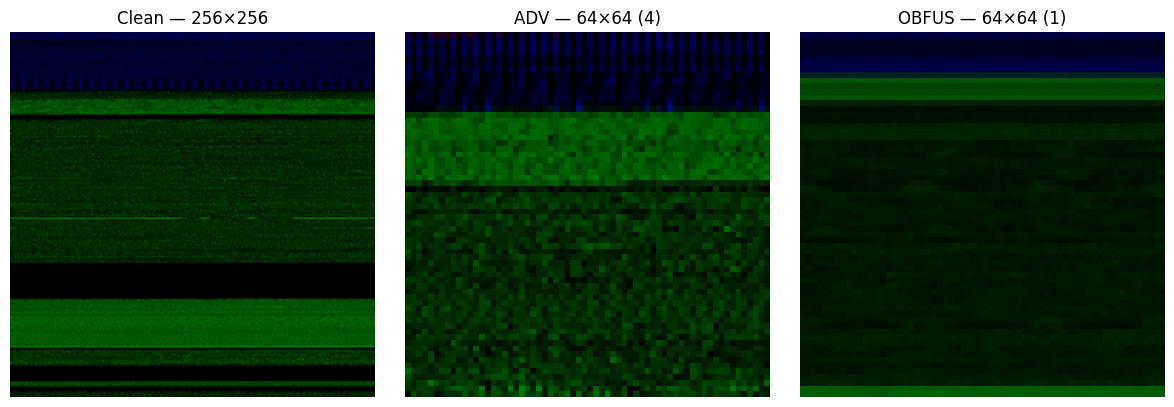

In [67]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

clean_path = manifest.iloc[0]["path"]

adv_64 = [
    (path, label) for path, label in adv_dataset.samples
    if Image.open(path).size == (64, 64)
]

obfus_64 = [
    (path, label) for path, label in obfus_dataset.samples
    if Image.open(path).size == (64, 64)
]

adv_path, adv_label = random.choice(adv_64)
obfus_path, obfus_label = random.choice(obfus_64)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, path, title in [
    (axes[0], clean_path, "Clean — 256×256"),
    (axes[1], adv_path, f"ADV — 64×64 ({adv_label})"),
    (axes[2], obfus_path, f"OBFUS — 64×64 ({obfus_label})"),
]:
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

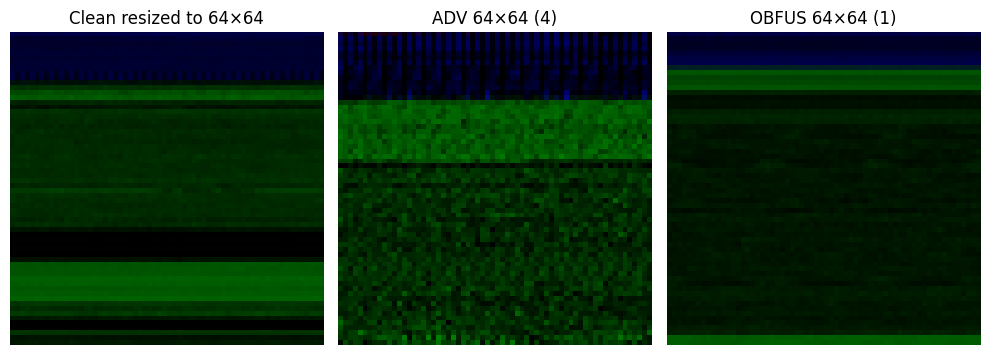

In [68]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

# Pick one clean image and resize it to 64x64 for visual comparison
clean_path = manifest.iloc[0]["path"]

adv_path, adv_label = random.choice([
    (path, label) for path, label in adv_dataset.samples
    if Image.open(path).size == (64, 64)
])

obfus_path, obfus_label = random.choice([
    (path, label) for path, label in obfus_dataset.samples
    if Image.open(path).size == (64, 64)
])

with Image.open(clean_path) as img:
    clean_64 = img.convert("RGB").resize((64, 64), Image.Resampling.LANCZOS)

with Image.open(adv_path) as img:
    adv_img = img.convert("RGB")

with Image.open(obfus_path) as img:
    obfus_img = img.convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

items = [
    (clean_64, "Clean resized to 64×64"),
    (adv_img, f"ADV 64×64 ({adv_label})"),
    (obfus_img, f"OBFUS 64×64 ({obfus_label})"),
]

for ax, (img, title) in zip(axes, items):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [69]:
import pandas as pd

# Check image dimensions, class counts, and exact-file overlap
print("=== IMAGE DIMENSIONS ===")
for dataset_name, folder in [
    ("Clean", data_root + "/train"),
    ("ADV", data_root + "/adv"),
    ("OBFUS", data_root + "/obfus"),
]:
    print(f"\n{dataset_name}:")
    # Use the previously audited file records where available
    if dataset_name in ["ADV", "OBFUS"]:
        subset = robust_df[robust_df["dataset"].str.lower() == dataset_name.lower()]
        print("Files:", len(subset))
        print("Unique exact-file hashes:", subset["sha256"].nunique())
        print("Class counts:")
        print(subset["label"].value_counts().sort_index().to_string())
    else:
        print("Clean training folder:", folder)

print("\n=== CLEAN-DATA OVERLAP ===")
for dataset_name in ["adv", "obfus"]:
    subset = robust_df[robust_df["dataset"].str.lower() == dataset_name].copy()
    subset["matches_clean"] = subset["sha256"].isin(clean_label_map.keys())

    print(f"\n{dataset_name.upper()}")
    print("Total files:", len(subset))
    print("Exact matches to clean data:", int(subset["matches_clean"].sum()))
    print("Files not matching clean data:", int((~subset["matches_clean"]).sum()))
    print("Label conflicts among exact matches:",
          sum(
              row["label"] not in clean_label_map.get(row["sha256"], [])
              for _, row in subset[subset["matches_clean"]].iterrows()
          ))

print("\nAudit complete. No files were changed.")

=== IMAGE DIMENSIONS ===

Clean:
Clean training folder: /content/drive/MyDrive/Malicious project work/Byteplot images/Image/train

ADV:
Files: 4840
Unique exact-file hashes: 3479
Class counts:
label
adware       440
banking      647
benign      1209
riskware    1093
sms         1451

OBFUS:
Files: 4547
Unique exact-file hashes: 4544
Class counts:
label
adware       360
banking      603
benign      1209
riskware     957
sms         1418

=== CLEAN-DATA OVERLAP ===

ADV
Total files: 4840
Exact matches to clean data: 1209
Files not matching clean data: 3631
Label conflicts among exact matches: 0

OBFUS
Total files: 4547
Exact matches to clean data: 1209
Files not matching clean data: 3338
Label conflicts among exact matches: 0

Audit complete. No files were changed.


In [70]:
from collections import Counter
from PIL import Image
import os
import pandas as pd

folders = {
    "clean_train": os.path.join(data_root, "train"),
    "adv": os.path.join(data_root, "adv"),
    "obfus": os.path.join(data_root, "obfus"),
}

rows = []

for dataset_name, folder in folders.items():
    for class_name in class_names:
        class_dir = os.path.join(folder, class_name)

        if not os.path.isdir(class_dir):
            print(f"Missing folder: {class_dir}")
            continue

        for filename in os.listdir(class_dir):
            if not filename.lower().endswith(
                (".png", ".jpg", ".jpeg", ".bmp", ".webp")
            ):
                continue

            path = os.path.join(class_dir, filename)

            try:
                with Image.open(path) as img:
                    rows.append({
                        "dataset": dataset_name,
                        "class": class_name,
                        "width": img.width,
                        "height": img.height,
                        "mode": img.mode,
                    })
            except Exception as e:
                print("Unreadable image:", path, str(e))

audit_df = pd.DataFrame(rows)

print("Image counts by dataset:")
print(audit_df.groupby("dataset").size().to_string())

print("\nDimensions by dataset:")
print(
    audit_df.groupby(["dataset", "width", "height"])
    .size()
    .rename("count")
    .to_string()
)

print("\nColor modes by dataset:")
print(
    audit_df.groupby(["dataset", "mode"])
    .size()
    .rename("count")
    .to_string()
)

Image counts by dataset:
dataset
adv             4840
clean_train    11686
obfus           4547

Dimensions by dataset:
dataset      width  height
adv          64     64         3631
             256    256        1209
clean_train  256    256       11686
obfus        64     64         3338
             256    256        1209

Color modes by dataset:
dataset      mode
adv          RGB      4840
clean_train  RGB     11686
obfus        RGB      4547


In [71]:
import os
import pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score

base_dir = os.path.join(data_root, "Image") if not data_root.endswith("/Image") else data_root

prediction_files = {
    "ADV": os.path.join(output_dir, "resnet50_adv_predictions.csv"),
    "OBFUS": os.path.join(output_dir, "resnet50_obfus_predictions.csv"),
}

rows = []

for dataset_name, csv_path in prediction_files.items():
    if not os.path.exists(csv_path):
        print(f"Missing prediction file: {csv_path}")
        continue

    df = pd.read_csv(csv_path)

    # Determine each image's original dimensions
    dimensions = []
    for path in df["image_path"]:
        try:
            with Image.open(path) as img:
                dimensions.append(f"{img.width}x{img.height}")
        except Exception:
            dimensions.append("unreadable")

    df["dimensions"] = dimensions

    for size, group in df.groupby("dimensions"):
        if size == "unreadable":
            continue

        rows.append({
            "dataset": dataset_name,
            "original_size": size,
            "images": len(group),
            "accuracy": accuracy_score(
                group["actual_label"], group["predicted_label"]
            ),
            "macro_f1": f1_score(
                group["actual_label"],
                group["predicted_label"],
                labels=class_names,
                average="macro",
                zero_division=0
            )
        })

results_by_size = pd.DataFrame(rows)

if results_by_size.empty:
    print("No results produced. Check the prediction CSV paths.")
else:
    print(results_by_size.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "macro_f1": "{:.4f}".format
        }
    ))

dataset original_size  images accuracy macro_f1
    ADV       256x256    1209   0.9752   0.1975
    ADV         64x64    3631   0.1862   0.1540
  OBFUS       256x256    1209   0.9752   0.1975
  OBFUS         64x64    3338   0.2900   0.1030


In [72]:
import os
import pandas as pd
from PIL import Image
from sklearn.metrics import classification_report

prediction_files = {
    "ADV": os.path.join(output_dir, "resnet50_adv_predictions.csv"),
    "OBFUS": os.path.join(output_dir, "resnet50_obfus_predictions.csv"),
}

for dataset_name, csv_path in prediction_files.items():
    df = pd.read_csv(csv_path)

    df["dimensions"] = [
        f"{Image.open(p).size[0]}x{Image.open(p).size[1]}"
        for p in df["image_path"]
    ]

    print(f"\n{'='*20} {dataset_name} {'='*20}")

    for size, group in df.groupby("dimensions"):
        print(f"\n--- {size}: {len(group)} images ---")

        print("Actual class counts:")
        print(group["actual_label"].value_counts().reindex(
            class_names, fill_value=0
        ).to_string())

        print("\nClassification report:")
        print(classification_report(
            group["actual_label"],
            group["predicted_label"],
            labels=class_names,
            zero_division=0,
            digits=3
        ))


==================== ADV ====================

--- 256x256: 1209 images ---
Actual class counts:
actual_label
adware         0
banking        0
benign      1209
riskware       0
sms            0

Classification report:
              precision    recall  f1-score   support

      adware      0.000     0.000     0.000         0
     banking      0.000     0.000     0.000         0
      benign      1.000     0.975     0.987      1209
    riskware      0.000     0.000     0.000         0
         sms      0.000     0.000     0.000         0

    accuracy                          0.975      1209
   macro avg      0.200     0.195     0.197      1209
weighted avg      1.000     0.975     0.987      1209


--- 64x64: 3631 images ---
Actual class counts:
actual_label
adware       440
banking      647
benign         0
riskware    1093
sms         1451

Classification report:
              precision    recall  f1-score   support

      adware      0.706     0.109     0.189       440
     bankin

In [73]:
import pandas as pd

manifest_path = (
    "/content/drive/MyDrive/Malicious project work/"
    "Byteplot images/clean_split_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

print("=== CLEAN SPLIT COUNTS ===")
print(pd.crosstab(manifest["split"], manifest["label"], margins=True))

print("\n=== DUPLICATE CONTENT HASHES ACROSS SPLITS ===")
split_counts = manifest.groupby("content_hash")["split"].nunique()
print("Hashes appearing in multiple splits:", int((split_counts > 1).sum()))

print("\n=== ROBUSTNESS FOLDER BENIGN COUNTS ===")
for name in ["ADV", "OBFUS"]:
    csv_path = f"{output_dir}/resnet50_{name.lower()}_predictions.csv"
    df = pd.read_csv(csv_path)
    print(f"\n{name}:")
    print(df["actual_label"].value_counts().to_string())

=== CLEAN SPLIT COUNTS ===
label       adware  banking  benign  riskware  sms    All
split                                                    
test           219      257     602       458  137   1673
train         1023     1198    2808      2135  641   7805
validation     219      257     602       457  138   1673
All           1461     1712    4012      3050  916  11151

=== DUPLICATE CONTENT HASHES ACROSS SPLITS ===
Hashes appearing in multiple splits: 0

=== ROBUSTNESS FOLDER BENIGN COUNTS ===

ADV:
actual_label
sms         1451
benign      1209
riskware    1093
banking      647
adware       440

OBFUS:
actual_label
sms         1418
benign      1209
riskware     957
banking      603
adware       360


In [74]:
import os
import pandas as pd

manifest_path = (
    "/content/drive/MyDrive/Malicious project work/"
    "Byteplot images/clean_split_manifest.csv"
)

manifest = pd.read_csv(manifest_path)
test_df = manifest[manifest["split"] == "test"].copy()

test_df["file_exists"] = test_df["path"].apply(os.path.isfile)

print("Clean test images:", len(test_df))
print("Existing files:", int(test_df["file_exists"].sum()))
print("Missing files:", int((~test_df["file_exists"]).sum()))

print("\nClass counts:")
print(test_df["label"].value_counts().reindex(class_names, fill_value=0))

print("\nExample paths:")
print(test_df[["path", "label"]].head(5).to_string(index=False))

Clean test images: 1673
Existing files: 1673
Missing files: 0

Class counts:
label
adware      219
banking     257
benign      602
riskware    458
sms         137
Name: count, dtype: int64

Example paths:
                                                                                                                                                                                 path    label
/content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/adware/1aef95b2a9ce7ad863940ff1799a0922b015a7924397f6259c08011d9e4071d425ed11ae3026295bf779604701e0e662.png   adware
                                 /content/drive/MyDrive/Malicious project work/Byteplot images/Image/test/benign/f39f338994a38aba31033ef39f0ee665db9ea79a0e157266d47d46fe13061f34.png   benign
                                                              /content/drive/MyDrive/Malicious project work/Byteplot images/Image/train/riskware/02c9508fc12f53ac246acb87b8b6b99f.png riskware
                               

In [75]:
import torch
import torch.nn.functional as F
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
from torchvision import transforms
import os

class ResolutionTestDataset(Dataset):
    def __init__(self, dataframe, mode="original"):
        self.df = dataframe.reset_index(drop=True)
        self.mode = mode
        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")

        if self.mode == "low_resolution":
            image = image.resize((64, 64), Image.Resampling.BILINEAR)
            image = image.resize((224, 224), Image.Resampling.BILINEAR)
        else:
            image = image.resize((224, 224), Image.Resampling.BILINEAR)

        image = self.normalize(self.to_tensor(image))
        label = class_names.index(row["label"])
        return image, label

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = os.path.join(output_dir, "resnet50_best.pth")
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, len(class_names))
model.load_state_dict(
    checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
)
model = model.to(device)
model.eval()

results = []

for mode in ["original", "low_resolution"]:
    dataset = ResolutionTestDataset(test_df, mode=mode)
    loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)

    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().tolist()

            y_true.extend(labels.tolist())
            y_pred.extend(preds)

    results.append({
        "condition": mode,
        "images": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    })

print(pd.DataFrame(results).to_string(
    index=False,
    formatters={
        "accuracy": "{:.4f}".format,
        "macro_f1": "{:.4f}".format
    }
))

     condition  images accuracy macro_f1
      original    1673   0.9044   0.8957
low_resolution    1673   0.5655   0.4568


In [76]:
from sklearn.metrics import classification_report
from torch.utils.data import DataLoader
import pandas as pd
import torch

class_results = []

for mode in ["original", "low_resolution"]:
    dataset = ResolutionTestDataset(test_df, mode=mode)
    loader = DataLoader(
        dataset, batch_size=32, shuffle=False, num_workers=0
    )

    y_true, y_pred = [], []

    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            y_pred.extend(outputs.argmax(dim=1).cpu().tolist())
            y_true.extend(labels.tolist())

    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        class_results.append({
            "condition": mode,
            "class": class_name,
            "precision": report[class_name]["precision"],
            "recall": report[class_name]["recall"],
            "f1": report[class_name]["f1-score"],
            "support": report[class_name]["support"]
        })

class_results_df = pd.DataFrame(class_results)

print(class_results_df.pivot(
    index="class",
    columns="condition",
    values="f1"
).round(4).to_string())

print("\nPer-class support:")
print(class_results_df[
    class_results_df["condition"] == "original"
][["class", "support"]].to_string(index=False))



condition  low_resolution  original
class                              
adware             0.2500    0.8825
banking            0.2022    0.8627
benign             0.6978    0.9421
riskware           0.5424    0.8889
sms                0.5914    0.9025

Per-class support:
   class  support
  adware    219.0
 banking    257.0
  benign    602.0
riskware    458.0
     sms    137.0


In [77]:
import os
import pandas as pd
import json

os.makedirs(output_dir, exist_ok=True)

# Save per-class F1 comparison
f1_pivot = class_results_df.pivot(
    index="class",
    columns="condition",
    values="f1"
).reset_index()

f1_pivot["f1_drop"] = (
    f1_pivot["original"] - f1_pivot["low_resolution"]
)

f1_csv = os.path.join(
    output_dir, "resnet50_resolution_sensitivity_by_class.csv"
)
f1_pivot.to_csv(f1_csv, index=False)

# Save overall metrics from the controlled experiment
overall_metrics = {
    "experiment": "Clean test image resolution degradation",
    "test_images": 1673,
    "original": {
        "accuracy": 0.9044,
        "macro_f1": 0.8957
    },
    "low_resolution_64x64_then_224x224": {
        "accuracy": 0.5655,
        "macro_f1": 0.4568
    },
    "accuracy_drop_percentage_points": 34.89,
    "macro_f1_drop_percentage_points": 43.89,
    "interpretation": (
        "Controlled resolution-degradation experiment; "
        "not evidence of adversarial attack robustness."
    )
}

json_path = os.path.join(
    output_dir, "resnet50_resolution_sensitivity_metrics.json"
)

with open(json_path, "w") as f:
    json.dump(overall_metrics, f, indent=2)

print("Saved files:")
print(f_csv if (f_csv := f1_csv) else f1_csv)
print(json_path)
print("\nPer-class comparison:")
print(f1_pivot.round(4).to_string(index=False))

Saved files:
/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_resolution_sensitivity_by_class.csv
/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_resolution_sensitivity_metrics.json

Per-class comparison:
   class  low_resolution  original  f1_drop
  adware          0.2500    0.8825   0.6325
 banking          0.2022    0.8627   0.6604
  benign          0.6978    0.9421   0.2443
riskware          0.5424    0.8889   0.3465
     sms          0.5914    0.9025   0.3111


In [78]:
import os
import pandas as pd
from PIL import Image

folders = {
    "ADV": os.path.join(data_root, "adv"),
    "OBFUS": os.path.join(data_root, "obfus"),
}

for name, root in folders.items():
    print(f"\n{'=' * 18} {name} {'=' * 18}")

    for class_name in class_names:
        class_dir = os.path.join(root, class_name)

        if not os.path.isdir(class_dir):
            print(f"{class_name}: MISSING FOLDER")
            continue

        files = sorted([
            f for f in os.listdir(class_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp"))
        ])

        print(f"\n{class_name}: {len(files)} images")
        for filename in files[:3]:
            path = os.path.join(class_dir, filename)
            with Image.open(path) as img:
                print(
                    f"  {filename} | {img.size[0]}x{img.size[1]} | "
                    f"{img.mode} | {img.format}"
                )


================== ADV ==================

adware: 440 images
  002fb7803cd8c0549bc7eb023458618520a3f0939e6ece1235a296491a7a13832839f25511fc886011534b6d2f5bdf2e.png | 64x64 | RGB | PNG
  01f36832a423c7e082ef45f781aca469e331f09e2d94b54e69ce30491f15578874a80fd0ad55a3a90be27d9a5c97fc72.png | 64x64 | RGB | PNG
  0347765164fd020685dd7fa47cee46ff07a80026d80136d81418656cca70d25c0ea0e2f21ab97a71231ed66a910aaca6.png | 64x64 | RGB | PNG

banking: 647 images
  000aec00a2b667aaf1224974aba7ee30b4b088e073368c605ee335fb8ee11b54.png | 64x64 | RGB | PNG
  007556ca146f4b2e9ac6bd51dc66be5130538d514f5aa04d60c1a0b079585ef3.png | 64x64 | RGB | PNG
  0084e4fa19aa0434a36129a7cf567c40214550d454d0e6d1b87b0b42e747e84c.png | 64x64 | RGB | PNG

benign: 1209 images
  00eac9c75cdb38f0158589d233d22cc78f69f0648159c9e8880e52e855b4bd4f.png | 256x256 | RGB | PNG
  01115bb5d043b775b1a9b90e4001035b6612c1030002c160219654738634a4b9.png | 256x256 | RGB | PNG
  0112ae505f5be62fa8f07ba6a2bfb0a47df65df5cbdf5428871c1766c235f44c.

In [79]:
import os
import hashlib
import pandas as pd

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

records = []

for dataset_name in ["adv", "obfus"]:
    for class_name in class_names:
        folder = os.path.join(data_root, dataset_name, class_name)

        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)

            if not os.path.isfile(path):
                continue

            records.append({
                "dataset": dataset_name.upper(),
                "class": class_name,
                "filename": filename,
                "sha256": sha256_file(path)
            })

comparison_df = pd.DataFrame(records)

for class_name in class_names:
    a = comparison_df[
        (comparison_df["dataset"] == "ADV") &
        (comparison_df["class"] == class_name)
    ]
    b = comparison_df[
        (comparison_df["dataset"] == "OBFUS") &
        (comparison_df["class"] == class_name)
    ]

    print(
        f"{class_name:10s} | "
        f"ADV files: {len(a):4d} | "
        f"OBFUS files: {len(b):4d} | "
        f"same filenames: {len(set(a.filename) & set(b.filename)):4d} | "
        f"same hashes: {len(set(a.sha256) & set(b.sha256)):4d}"
    )


adware     | ADV files:  440 | OBFUS files:  360 | same filenames:  360 | same hashes:    0
banking    | ADV files:  647 | OBFUS files:  603 | same filenames:  601 | same hashes:    0
benign     | ADV files: 1209 | OBFUS files: 1209 | same filenames: 1209 | same hashes: 1206
riskware   | ADV files: 1093 | OBFUS files:  957 | same filenames:  952 | same hashes:    0
sms        | ADV files: 1451 | OBFUS files: 1418 | same filenames: 1415 | same hashes:    0


Filename: 002fb7803cd8c0549bc7eb023458618520a3f0939e6ece1235a296491a7a13832839f25511fc886011534b6d2f5bdf2e.png
ADV dimensions: (64, 64)
OBFUS dimensions: (64, 64)

ADV image:


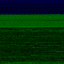


OBFUS image:


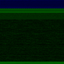


Mean absolute pixel difference: 11.8
SSIM: 0.6561


In [80]:
import os
import numpy as np
from PIL import Image
from IPython.display import display
from skimage.metrics import structural_similarity as ssim

class_name = "adware"

adv_dir = os.path.join(data_root, "adv", class_name)
obfus_dir = os.path.join(data_root, "obfus", class_name)

shared_names = sorted(
    set(os.listdir(adv_dir)) & set(os.listdir(obfus_dir))
)

if not shared_names:
    print("No shared filenames found.")
else:
    filename = shared_names[0]
    adv_path = os.path.join(adv_dir, filename)
    obfus_path = os.path.join(obfus_dir, filename)

    adv_img = Image.open(adv_path).convert("RGB")
    obfus_img = Image.open(obfus_path).convert("RGB")

    print("Filename:", filename)
    print("ADV dimensions:", adv_img.size)
    print("OBFUS dimensions:", obfus_img.size)

    print("\nADV image:")
    display(adv_img)

    print("\nOBFUS image:")
    display(obfus_img)

    if adv_img.size == obfus_img.size:
        a = np.asarray(adv_img).astype(np.float32)
        b = np.asarray(obfus_img).astype(np.float32)

        print("\nMean absolute pixel difference:", round(float(np.abs(a-b).mean()), 3))
        print("SSIM:", round(float(ssim(
            a.astype(np.uint8),
            b.astype(np.uint8),
            channel_axis=2,
            data_range=255
        )), 4))
    else:
        print("\nDifferent dimensions; compare after resizing both to 256x256.")

In [81]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import structural_similarity as ssim

records = []

for class_name in ["adware", "banking", "riskware", "sms"]:
    adv_dir = os.path.join(data_root, "adv", class_name)
    obfus_dir = os.path.join(data_root, "obfus", class_name)

    shared = sorted(
        set(os.listdir(adv_dir)) & set(os.listdir(obfus_dir))
    )

    # Use up to 25 matching filenames per class
    for filename in shared[:25]:
        try:
            with Image.open(os.path.join(adv_dir, filename)) as im:
                adv_img = im.convert("RGB").resize((64, 64))
                a = np.asarray(adv_img)

            with Image.open(os.path.join(obfus_dir, filename)) as im:
                obfus_img = im.convert("RGB").resize((64, 64))
                b = np.asarray(obfus_img)

            records.append({
                "class": class_name,
                "filename": filename,
                "mean_absolute_difference": float(
                    np.abs(a.astype(np.float32) -
                           b.astype(np.float32)).mean()
                ),
                "ssim": float(ssim(
                    a, b, channel_axis=2, data_range=255
                ))
            })
        except Exception as e:
            print("Skipped:", filename, e)

similarity_df = pd.DataFrame(records)

print("Compared pairs:", len(similarity_df))
print("\nSummary by class:")
print(
    similarity_df.groupby("class")[
        ["mean_absolute_difference", "ssim"]
    ].agg(["mean", "median", "min", "max"]).round(4).to_string()
)

print("\nOverall summary:")
print(
    similarity_df[
        ["mean_absolute_difference", "ssim"]
    ].describe().round(4).to_string()
)

Compared pairs: 100

Summary by class:
         mean_absolute_difference                              ssim                        
                             mean   median     min      max    mean  median     min     max
class                                                                                      
adware                    11.4168  11.5598  8.7619  13.8891  0.6726  0.6726  0.6192  0.7098
banking                   12.2680  11.8658  9.6445  17.5487  0.6710  0.6820  0.5790  0.7485
riskware                  13.2725  12.0898  9.6686  17.7377  0.6442  0.6268  0.5744  0.7363
sms                       12.3114  13.1110  6.4184  16.0942  0.6364  0.6200  0.5770  0.7874

Overall summary:
       mean_absolute_difference      ssim
count                  100.0000  100.0000
mean                    12.3172    0.6560
std                      2.2718    0.0487
min                      6.4184    0.5744
25%                     10.9089    0.6182
50%                     11.8765    0.6673
75%  

In [82]:
print(
    similarity_df.groupby("class").agg(
        pairs=("ssim", "count"),
        mean_ssim=("ssim", "mean"),
        std_ssim=("ssim", "std"),
        mean_pixel_difference=("mean_absolute_difference", "mean")
    ).round(4)
)

print("\nPair counts by SSIM range:")
print(
    pd.cut(
        similarity_df["ssim"],
        bins=[0, 0.60, 0.65, 0.70, 0.80, 1.00],
        right=False
    ).value_counts().sort_index()
)

          pairs  mean_ssim  std_ssim  mean_pixel_difference
class                                                      
adware       25     0.6726    0.0262                11.4168
banking      25     0.6710    0.0447                12.2680
riskware     25     0.6442    0.0573                13.2725
sms          25     0.6364    0.0522                12.3114

Pair counts by SSIM range:
ssim
[0.0, 0.6)     16
[0.6, 0.65)    28
[0.65, 0.7)    38
[0.7, 0.8)     18
[0.8, 1.0)      0
Name: count, dtype: int64


In [83]:
import os
import pandas as pd

output_dir = "/content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs"
os.makedirs(output_dir, exist_ok=True)

pair_path = os.path.join(output_dir, "adv_obfus_image_similarity_pairs.csv")
summary_path = os.path.join(output_dir, "adv_obfus_image_similarity_summary.csv")

similarity_df.to_csv(pair_path, index=False)

summary_df = (
    similarity_df.groupby("class")
    .agg(
        pairs=("ssim", "count"),
        mean_ssim=("ssim", "mean"),
        std_ssim=("ssim", "std"),
        median_ssim=("ssim", "median"),
        mean_pixel_difference=("mean_absolute_difference", "mean"),
        median_pixel_difference=("mean_absolute_difference", "median"),
    )
    .reset_index()
    .round(4)
)

summary_df.to_csv(summary_path, index=False)

print("Saved pair-level results:", pair_path)
print("Saved class summary:", summary_path)
print("\n", summary_df.to_string(index=False))

Saved pair-level results: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/adv_obfus_image_similarity_pairs.csv
Saved class summary: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/adv_obfus_image_similarity_summary.csv

    class  pairs  mean_ssim  std_ssim  median_ssim  mean_pixel_difference  median_pixel_difference
  adware     25     0.6726    0.0262       0.6726                11.4168                  11.5598
 banking     25     0.6710    0.0447       0.6820                12.2680                  11.8658
riskware     25     0.6442    0.0573       0.6268                13.2725                  12.0898
     sms     25     0.6364    0.0522       0.6200                12.3114                  13.1110


In [86]:
print("ADV columns:", adv_df.columns.tolist())
print("OBFUS columns:", obfus_df.columns.tolist())

print("\nADV preview:")
display(adv_df.head(3))

print("\nOBFUS preview:")
display(obfus_df.head(3))

ADV columns: ['image_path', 'actual_label', 'predicted_label']
OBFUS columns: ['image_path', 'actual_label', 'predicted_label']

ADV preview:


,image_path,actual_label,predicted_label
0,/content/byteplot_eval/adv/adware/002fb7803cd8...,adware,riskware
1,/content/byteplot_eval/adv/adware/01f36832a423...,adware,riskware
2,/content/byteplot_eval/adv/adware/0347765164fd...,adware,riskware



OBFUS preview:


,image_path,actual_label,predicted_label
0,/content/byteplot_eval/obfus/adware/002fb7803c...,adware,riskware
1,/content/byteplot_eval/obfus/adware/01f36832a4...,adware,riskware
2,/content/byteplot_eval/obfus/adware/0347765164...,adware,riskware


In [87]:
import pandas as pd
import os

def class_error_summary(df, dataset_name):
    rows = []

    for label, group in df.groupby("actual_label"):
        correct_mask = group["actual_label"] == group["predicted_label"]
        incorrect = group.loc[~correct_mask, "predicted_label"]

        rows.append({
            "dataset": dataset_name,
            "class": label,
            "samples": len(group),
            "correct": int(correct_mask.sum()),
            "accuracy": round(float(correct_mask.mean()), 4),
            "most_common_wrong_prediction": (
                incorrect.mode().iloc[0] if len(incorrect) else "None"
            )
        })

    return pd.DataFrame(rows)

error_summary = pd.concat([
    class_error_summary(adv_df, "ADV"),
    class_error_summary(obfus_df, "OBFUS")
], ignore_index=True)

print(error_summary.to_string(index=False))

summary_path = os.path.join(
    output_dir, "resnet50_adv_obfus_class_error_summary.csv"
)
error_summary.to_csv(summary_path, index=False)
print("\nSaved:", summary_path)

dataset    class  samples  correct  accuracy most_common_wrong_prediction
    ADV   adware      440       48    0.1091                     riskware
    ADV  banking      647      260    0.4019                       benign
    ADV   benign     1209     1179    0.9752                      banking
    ADV riskware     1093      345    0.3156                      banking
    ADV      sms     1451       23    0.0159                      banking
  OBFUS   adware      360        6    0.0167                     riskware
  OBFUS  banking      603        0    0.0000                     riskware
  OBFUS   benign     1209     1179    0.9752                      banking
  OBFUS riskware      957      931    0.9728                      banking
  OBFUS      sms     1418       31    0.0219                     riskware

Saved: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_adv_obfus_class_error_summary.csv


In [88]:
import os
import pandas as pd

adv_df = pd.read_csv(os.path.join(
    output_dir, "resnet50_adv_predictions.csv"
))
obfus_df = pd.read_csv(os.path.join(
    output_dir, "resnet50_obfus_predictions.csv"
))

adv_df["filename"] = adv_df["image_path"].map(os.path.basename)
obfus_df["filename"] = obfus_df["image_path"].map(os.path.basename)

comparison = adv_df.merge(
    obfus_df,
    on=["filename", "actual_label"],
    suffixes=("_adv", "_obfus")
)

comparison["prediction_agrees"] = (
    comparison["predicted_label_adv"] ==
    comparison["predicted_label_obfus"]
)

print("Matched filename/class pairs:", len(comparison))
print("Predictions agree:", int(comparison["prediction_agrees"].sum()))
print("Predictions disagree:", int((~comparison["prediction_agrees"]).sum()))
print(
    "Agreement rate:",
    round(comparison["prediction_agrees"].mean() * 100, 2), "%"
)

print("\nAgreement by class:")
print(
    comparison.groupby("actual_label")["prediction_agrees"]
    .agg(["count", "sum", "mean"])
    .assign(agreement_pct=lambda x: x["mean"] * 100)
    .drop(columns="mean")
    .round(2)
    .to_string()
)

Matched filename/class pairs: 4537
Predictions agree: 1955
Predictions disagree: 2582
Agreement rate: 43.09 %

Agreement by class:
              count   sum  agreement_pct
actual_label                            
adware          360   163          45.28
banking         601   130          21.63
benign         1209  1209         100.00
riskware        952   286          30.04
sms            1415   167          11.80


In [89]:
comparison["adv_correct"] = (
    comparison["predicted_label_adv"] == comparison["actual_label"]
)
comparison["obfus_correct"] = (
    comparison["predicted_label_obfus"] == comparison["actual_label"]
)

comparison["outcome"] = comparison.apply(
    lambda r: (
        "Correct in both" if r["adv_correct"] and r["obfus_correct"]
        else "ADV only correct" if r["adv_correct"]
        else "OBFUS only correct" if r["obfus_correct"]
        else "Incorrect in both"
    ),
    axis=1
)

print("Outcome counts across matched pairs:")
print(comparison["outcome"].value_counts().to_string())

print("\nOutcome counts by class:")
print(pd.crosstab(
    comparison["actual_label"],
    comparison["outcome"]
).to_string())

Outcome counts across matched pairs:
outcome
Incorrect in both     2112
Correct in both       1458
OBFUS only correct     684
ADV only correct       283

Outcome counts by class:
outcome       ADV only correct  Correct in both  Incorrect in both  OBFUS only correct
actual_label                                                                          
adware                      18                0                336                   6
banking                    246                0                355                   0
benign                       0             1179                 30                   0
riskware                     7              272                 19                 654
sms                         12                7               1372                  24


In [90]:
import os
import pandas as pd

comparison_path = os.path.join(
    output_dir, "resnet50_adv_obfus_matched_pair_outcomes.csv"
)
class_outcome_path = os.path.join(
    output_dir, "resnet50_adv_obfus_outcomes_by_class.csv"
)

comparison.to_csv(comparison_path, index=False)

outcomes_by_class = pd.crosstab(
    comparison["actual_label"],
    comparison["outcome"]
).reset_index()

outcomes_by_class.to_csv(class_outcome_path, index=False)

print("Saved paired predictions:", comparison_path)
print("Saved class-wise outcomes:", class_outcome_path)
print("\nClass-wise outcome table:")
print(outcomes_by_class.to_string(index=False))

Saved paired predictions: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_adv_obfus_matched_pair_outcomes.csv
Saved class-wise outcomes: /content/drive/MyDrive/Malicious project work/Byteplot images/model_outputs/resnet50_adv_obfus_outcomes_by_class.csv

Class-wise outcome table:
actual_label  ADV only correct  Correct in both  Incorrect in both  OBFUS only correct
      adware                18                0                336                   6
     banking               246                0                355                   0
      benign                 0             1179                 30                   0
    riskware                 7              272                 19                 654
         sms                12                7               1372                  24
